## 0. Setup

In [ ]:
from importlib.metadata import version
import sys

print("Python:", sys.version.split()[0], "|", sys.executable)
for package in ("huggingface-hub", "soundfile", "pyarrow", "scikit-learn", "torch",
                "transformers", "numpy", "pandas", "scipy", "matplotlib"):
    print(f"{package}: {version(package)}")

Python: 3.13.5 | c:\Users\Aisha\venvs\nabra\Scripts\python.exe
huggingface-hub: 1.33.0
soundfile: 0.14.0
pyarrow: 26.0.1
scikit-learn: 1.9.1
torch: 2.14.1+cu126
transformers: 5.18.0
numpy: 2.5.3
pandas: 3.0.6
scipy: 1.18.1
matplotlib: 3.11.2


In [ ]:
import os, io, re, json, glob, time, shutil, hashlib, sys
from collections import defaultdict
import numpy as np, pandas as pd, soundfile as sf
import matplotlib.pyplot as plt
from huggingface_hub import HfApi, hf_hub_download, login
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

REPO_ID    = "ArabicSpeech/ArA-DF-2026"
REVISION   = "2b1f042dc166b1d372841cb0d7110661ea5b2a93"
LOCAL_ROOT = None
AUDIO_ROOT = r"C:\Users\Aisha\nabra_data\aradf_audio"
EXTRACT_SPLITS = ["train", "dev", "track-1_development_test", "track-2_development_test"]
MAX_SHARDS_PER_SPLIT = None
SEED = 42

os.makedirs(AUDIO_ROOT, exist_ok=True)
np.random.seed(SEED)

HF_TOKEN = None
try:
    from google.colab import userdata; HF_TOKEN = userdata.get("HF_TOKEN")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN: login(HF_TOKEN)

def list_files():
    if LOCAL_ROOT:
        return sorted(os.path.relpath(p, LOCAL_ROOT).replace(os.sep, "/")
                      for p in glob.glob(f"{LOCAL_ROOT}/**/*", recursive=True) if os.path.isfile(p))
    return sorted(HfApi().list_repo_files(REPO_ID, repo_type="dataset", revision=REVISION, token=HF_TOKEN))

def fetch(path):
    return os.path.join(LOCAL_ROOT, path) if LOCAL_ROOT else hf_hub_download(REPO_ID, path, repo_type="dataset", revision=REVISION, token=HF_TOKEN)

FILES = list_files()
print(len(FILES), "files in repo")

c:\Users\Aisha\venvs\nabra\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


114 files in repo


**Result:** setup OK, Hub connected.

## 1. Load metadata

In [ ]:
SPLITS = ["train", "dev", "track-1_development_test", "track-2_development_test", "track-1_test", "track-2_test"]
def meta_path(s):
    return f"metadata/{s}.parquet" if s in ("train", "dev") else f"metadata_labeled/{s}.parquet"

ALL = pd.concat([pd.read_parquet(fetch(meta_path(s))).assign(cfg=s) for s in SPLITS], ignore_index=True)
ALL["label_name"] = ALL["label"].map({1: "bonafide", 0: "spoof"})

def parse_name(i):
    p = str(i).split("_")
    return (p[0], p[1]) if len(p) >= 4 and p[2] in ("train", "dev") else ("unknown", "unknown")
ALL[["dialect", "gender"]] = pd.DataFrame(ALL["id"].map(parse_name).tolist(), index=ALL.index)
TD = ALL[ALL.cfg.isin(["train", "dev"])]
print(ALL.shape); ALL.head(3)

c:\Users\Aisha\venvs\nabra\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Aisha\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
c:\Users\Aisha\venvs\nabra\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default

(345672, 14)


,id,file_name,split,label,duration_sec,sample_rate,channels,subtype,sha256,flac_bytes,cfg,label_name,dialect,gender
0,EGY_Female_train_0001871,data/train/train-000000.tar::EGY_Female_train_...,train,0,5.110,16000,1,PCM_16,de0c011b67878c539680fed53c9b4eebcf822c23da9983...,66690,train,spoof,EGY,Female
1,EGY_Female_train_0002162,data/train/train-000000.tar::EGY_Female_train_...,train,1,13.480,16000,1,PCM_16,b4d46031821fecf5f09e341158c51f61503f88eaf0833c...,231991,train,bonafide,EGY,Female
2,EGY_Female_train_0028818,data/train/train-000000.tar::EGY_Female_train_...,train,1,12.121,16000,1,PCM_16,cb12ac1d895b30bc69a9cbd0ae727e2825493c260ef144...,219006,train,bonafide,EGY,Female


**Result:** 345,672 labeled clips in 6 splits (matches the paper).

## 2. Metadata EDA

label_name                bonafide   spoof     All
cfg                                               
dev                           6952   14048   21000
track-1_development_test      4097   11926   16023
track-1_test                 36903  107307  144210
track-2_development_test      3510   10683   14193
track-2_test                 31490   96256  127746
train                         7500   15000   22500
All                          90452  255220  345672 

label_name     bonafide  spoof    All
cfg   dialect                        
dev   EGY          1452   3077   4529
      Gulf         5015   9997  15012
      MSA           485    974   1459
train EGY          2500   5000   7500
      Gulf         2500   5000   7500
      MSA          2500   5000   7500
All               14452  29048  43500 

label_name             bonafide  spoof
cfg   dialect gender                  
dev   EGY     Female        373    794
              Male         1024   2184
              Unknown        55     99


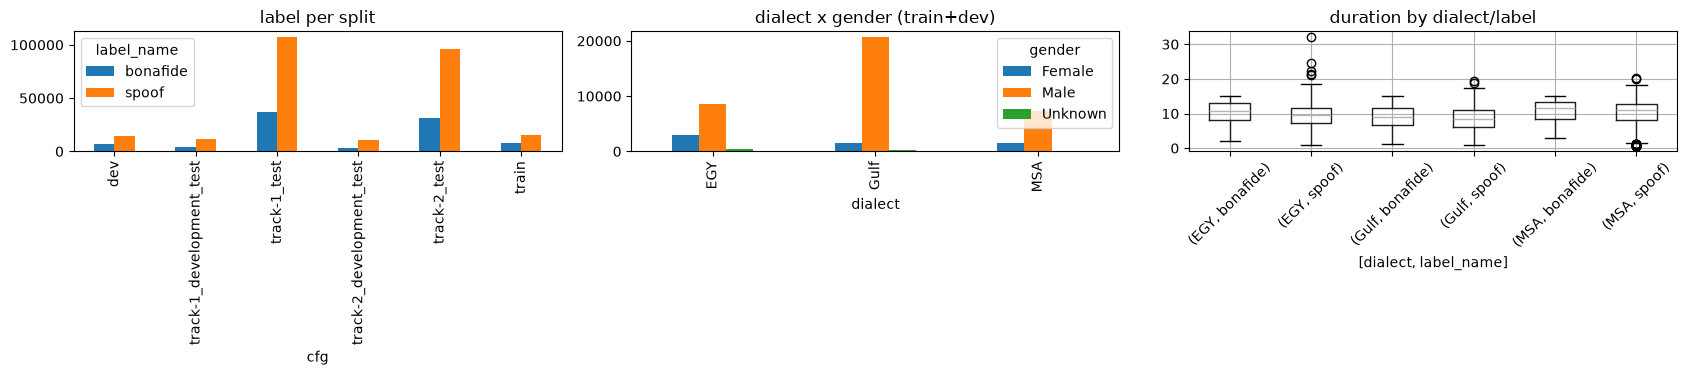

In [ ]:
print(pd.crosstab(ALL.cfg, ALL.label_name, margins=True), "\n")
print(pd.crosstab([TD.cfg, TD.dialect], [TD.label_name], margins=True), "\n")
print(pd.crosstab([TD.cfg, TD.dialect, TD.gender], TD.label_name), "\n")
print(TD.groupby(["cfg", "dialect", "label_name"])["duration_sec"].describe(percentiles=[.05, .5, .95]).round(2))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
pd.crosstab(ALL.cfg, ALL.label_name).plot.bar(ax=ax[0], title="label per split")
pd.crosstab([TD.dialect], [TD.gender]).plot.bar(ax=ax[1], title="dialect x gender (train+dev)")
TD.boxplot("duration_sec", by=["dialect", "label_name"], ax=ax[2], rot=45); ax[2].set_title("duration by dialect/label")
plt.suptitle(""); plt.tight_layout(); plt.show()

**Result:** bona fide : spoof ≈ 1 : 2 in every split; dev is 71% Gulf; train is 81% male.

In [ ]:
long_ = ALL[ALL.duration_sec > 15.5]; short_ = ALL[ALL.duration_sec < 1.0]
print("clips > 15.5 s:"); print(pd.crosstab(long_.cfg, long_.label_name))
print("\nclips < 1 s:");   print(pd.crosstab(short_.cfg, short_.label_name))
print("\nlongest clips:"); print(ALL.nlargest(8, "duration_sec")[["cfg", "id", "label_name", "duration_sec"]])

clips > 15.5 s:
label_name                bonafide  spoof
cfg                                      
dev                              0     15
track-1_development_test         0    187
track-1_test                     5   1583
track-2_development_test         0    161
track-2_test                     0   1315
train                            0     51

clips < 1 s:
label_name                spoof
cfg                            
dev                           6
track-1_development_test     10
track-1_test                 97
track-2_development_test      5
track-2_test                 66
train                        33

longest clips:
                             cfg            id label_name  duration_sec
111824              track-1_test  test_3362593      spoof    106.752000
323694              track-2_test  test_8448417      spoof    106.718937
49574   track-1_development_test  test_0375788      spoof     95.040000
52912   track-1_development_test  test_0590156      spoof     95.040000
53

**Result:** almost all clips over 15.5 s or under 1 s are spoof.

## 3. Data pipeline functions

In [ ]:
import os, io, json, tarfile
import numpy as np, pandas as pd, soundfile as sf

SR = 16000
REPO_ID = "ArabicSpeech/ArA-DF-2026"

def iter_tar(tar_path):
    with tarfile.open(tar_path) as tf:
        for m in tf:
            if m.isfile() and m.name.endswith(".flac"):
                yield os.path.basename(m.name)[:-5], tf.extractfile(m).read()

def prepare_audio(splits, audio_root, keep_ids=None, token=None, max_shards=None, on_clip=None):
    from huggingface_hub import HfApi, hf_hub_download
    files = HfApi().list_repo_files(REPO_ID, repo_type="dataset", token=token)
    for split in splits:
        tars = sorted(f for f in files if f.startswith(f"data/{split}/") and f.endswith(".tar"))[:max_shards]
        os.makedirs(f"{audio_root}/{split}", exist_ok=True)
        for t in tars:
            local = hf_hub_download(REPO_ID, t, repo_type="dataset", token=token)
            extract_tar(local, split, audio_root, keep_ids, on_clip)

def extract_tar(local_tar, split, audio_root, keep_ids=None, on_clip=None):
    n = 0
    for cid, flac in iter_tar(local_tar):
        if on_clip: on_clip(split, cid, flac)
        if keep_ids is not None and cid not in keep_ids: continue
        p = f"{audio_root}/{split}/{cid}.flac"
        if not os.path.exists(p):
            with open(p, "wb") as f: f.write(flac)
        n += 1
    return n

def load_wave(path):
    x, sr = sf.read(path, dtype="float32", always_2d=False)
    if x.ndim > 1: x = x.mean(1)
    assert sr == SR, f"{path}: sr={sr}"
    return x

def trim_silence(x, top_db=40.0, frame=400, hop=160):
    if len(x) < frame: return x
    nf = 1 + (len(x) - frame) // hop
    idx = np.arange(frame)[None, :] + hop * np.arange(nf)[:, None]
    e = 10 * np.log10((x[idx] ** 2).mean(1) + 1e-10)
    v = np.flatnonzero(e > e.max() - top_db)
    return x[v[0] * hop: v[-1] * hop + frame] if len(v) else x

def rms_normalize(x, target_dbfs=-23.0):
    rms = np.sqrt(np.mean(x ** 2) + 1e-12)
    return np.clip(x * (10 ** (target_dbfs / 20) / rms), -1, 1).astype(np.float32)

def crop_or_pad(x, n, train, rng=np.random):
    if len(x) == 0: return np.zeros(n, np.float32)
    if len(x) < n: x = np.tile(x, int(np.ceil(n / len(x))))
    if len(x) == n: return x[:n]
    start = rng.randint(0, len(x) - n + 1) if train else 0
    return x[start:start + n]

def augment(x, rng=np.random, p=0.5):
    from scipy.signal import resample_poly, butter, sosfilt
    if rng.rand() < p:
        x = x * 10 ** (rng.uniform(-6, 6) / 20)
    if rng.rand() < p:
        snr = rng.uniform(10, 40); pw = np.mean(x ** 2) + 1e-12
        x = x + rng.randn(len(x)).astype(np.float32) * np.sqrt(pw / 10 ** (snr / 10))
    if rng.rand() < p * 0.5:
        y = resample_poly(x, 1, 2)
        y = sosfilt(butter(4, [300, 3400], btype="band", fs=8000, output="sos"), y)
        x = resample_poly(y, 2, 1)[:len(x)]
    return np.clip(x, -1, 1).astype(np.float32)

def make_windows(x, n):
    if len(x) <= n: return crop_or_pad(x, n, train=False)[None, :]
    starts = list(range(0, len(x) - n + 1, n))
    if starts[-1] + n < len(x): starts.append(len(x) - n)
    return np.stack([x[s:s + n] for s in starts])

DEFAULT_CONFIG = dict(crop_sec=64600 / 16000, trim_silence=False, normalize="none", augment_p=0.5)

def clean_wave(x, cfg):
    if cfg.get("trim_silence"): x = trim_silence(x)
    if cfg.get("normalize") == "rms": x = rms_normalize(x)
    return x.astype(np.float32)

def preprocess(x, cfg, train, rng=np.random):
    x = clean_wave(x, cfg); n = int(round(cfg["crop_sec"] * SR))
    if not train: return make_windows(x, n).astype(np.float32)
    x = crop_or_pad(x, n, True, rng)
    if cfg.get("augment_p", 0) > 0: x = augment(x, rng, cfg["augment_p"])
    return x.astype(np.float32)

def make_dataset(manifest, audio_root, cfg, train):
    import torch
    df = manifest[manifest["keep"]].reset_index(drop=True)
    class AraDFDataset(torch.utils.data.Dataset):
        def __init__(self): self.df = df
        def __len__(self): return len(self.df)
        def __getitem__(self, i):
            r = self.df.iloc[i]
            x = preprocess(load_wave(os.path.join(audio_root, r["path"])), cfg, train)
            return torch.from_numpy(x), int(r["label"]), r["id"]
    return AraDFDataset()

def collate_windows(batch):
    import torch
    waves = torch.cat([b[0] for b in batch]); counts = [b[0].shape[0] for b in batch]
    return waves, torch.tensor([b[1] for b in batch]), [b[2] for b in batch], counts

def make_loader(ds, batch_size=16, train=True, balanced=False, num_workers=0):
    import torch
    if not train:
        return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=False,
                                           num_workers=num_workers, collate_fn=collate_windows)
    sampler = None
    if balanced:
        y = ds.df["label"].to_numpy(dtype=np.int64); w = 1.0 / np.bincount(y, minlength=2)[y]
        sampler = torch.utils.data.WeightedRandomSampler(torch.as_tensor(w, dtype=torch.double),
                                                         num_samples=len(y), replacement=True)
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=(sampler is None),
                                       sampler=sampler, num_workers=num_workers, drop_last=True)

def class_weights(manifest):
    y = manifest[manifest["keep"]]["label"].values
    c = np.bincount(y, minlength=2); return (len(y) / (2 * c)).tolist()

def compute_eer(labels, scores):
    from sklearn.metrics import roc_curve
    fpr, tpr, _ = roc_curve(np.asarray(labels), np.asarray(scores), pos_label=1)
    fnr = 1 - tpr; i = np.nanargmin(np.abs(fnr - fpr))
    return float(100 * (fpr[i] + fnr[i]) / 2)

In [ ]:
import types
AD = types.SimpleNamespace(**{k: v for k, v in globals().items() if k in (
    "iter_tar", "extract_tar", "load_wave", "trim_silence", "rms_normalize", "crop_or_pad", "augment",
    "DEFAULT_CONFIG", "preprocess", "make_dataset", "make_loader", "class_weights", "compute_eer", "SR",
    "make_windows", "clean_wave", "collate_windows")})
print("pipeline functions ready")

pipeline functions ready


## 4. Audio extraction and acoustic features

In [ ]:
def acoustic_features(x16, sr=16000, frame=400, hop=160, nfft=512):
    x = x16.astype(np.float32) / 32768
    out = dict(peak=float(np.abs(x).max(initial=0)), clip_frac=float(np.mean(np.abs(x16) >= 32700)),
               dc=float(x.mean()) if len(x) else 0.0, rms_db=float(20 * np.log10(np.sqrt(np.mean(x ** 2) + 1e-12))))
    if len(x) < frame:
        return {**out, "lead_sil": 0.0, "trail_sil": 0.0, "speech_ratio": 0.0, "snr_est": 0.0, "rolloff95": 0.0, "centroid": 0.0}, None
    nf = 1 + (len(x) - frame) // hop
    fr = x[np.arange(frame)[None, :] + hop * np.arange(nf)[:, None]]
    e = 10 * np.log10((fr ** 2).mean(1) + 1e-10)
    v = e > max(e.max() - 40, -70)
    iv = np.flatnonzero(v)
    spec = np.abs(np.fft.rfft(fr[v] * np.hanning(frame), nfft)) ** 2 if v.any() else np.zeros((1, nfft // 2 + 1))
    ps = spec.mean(0); f = np.fft.rfftfreq(nfft, 1 / sr); c = np.cumsum(ps) / (ps.sum() + 1e-12)
    out.update(lead_sil=float(iv[0] * hop / sr) if len(iv) else 0.0,
               trail_sil=float((nf - 1 - iv[-1]) * hop / sr) if len(iv) else 0.0,
               speech_ratio=float(v.mean()), snr_est=float(np.percentile(e, 95) - np.percentile(e, 10)),
               rolloff95=float(f[min(np.searchsorted(c, 0.95), len(f) - 1)]), centroid=float((f * ps).sum() / (ps.sum() + 1e-12)))
    return out, np.log10(ps + 1e-12)

FEATS, LTAS = [], defaultdict(lambda: [np.zeros(257), 0])
lab_of = dict(zip(zip(ALL.cfg, ALL.id), ALL.label))

def on_clip(split, cid, flac):
    x, sr = sf.read(io.BytesIO(flac), dtype="int16", always_2d=False)
    if x.ndim > 1: x = x.mean(1).astype("int16")
    d, spec = acoustic_features(x, sr)
    FEATS.append(dict(cfg=split, id=cid, sr=sr, dur=len(x) / sr,
                      wav_md5=hashlib.md5(x.tobytes()).hexdigest(),
                      trim_md5=hashlib.md5(np.trim_zeros(np.where(np.abs(x) > 8, x, 0)).tobytes()).hexdigest(), **d))
    if spec is not None:
        k = (split, lab_of.get((split, cid))); LTAS[k][0] += spec; LTAS[k][1] += 1

t0 = time.time()
for split in EXTRACT_SPLITS:
    tars = sorted(f for f in FILES if f.startswith(f"data/{split}/") and f.endswith(".tar"))[:MAX_SHARDS_PER_SPLIT]
    os.makedirs(f"{AUDIO_ROOT}/{split}", exist_ok=True)
    for t in tars:
        n = AD.extract_tar(fetch(t), split, AUDIO_ROOT, on_clip=on_clip)
        print(f"{t}: {n} clips | {time.time() - t0:.0f}s")

F = pd.DataFrame(FEATS).merge(ALL[["cfg", "id", "label", "label_name", "dialect", "gender", "duration_sec", "sha256"]], on=["cfg", "id"], how="left")
print(F.shape, "| missing labels:", int(F.label.isna().sum()))

data/train/train-000000.tar: 4096 clips | 119s
data/train/train-000001.tar: 4096 clips | 243s
data/train/train-000002.tar: 4096 clips | 431s
data/train/train-000003.tar: 4096 clips | 712s
data/train/train-000004.tar: 4096 clips | 937s
data/train/train-000005.tar: 2020 clips | 1059s
data/dev/dev-000000.tar: 4096 clips | 1368s
data/dev/dev-000001.tar: 4096 clips | 1632s
data/dev/dev-000002.tar: 4096 clips | 1889s
data/dev/dev-000003.tar: 4096 clips | 2145s
data/dev/dev-000004.tar: 4096 clips | 2419s
data/dev/dev-000005.tar: 520 clips | 2458s
data/track-1_development_test/track-1_development_test-000000.tar: 4096 clips | 2792s
data/track-1_development_test/track-1_development_test-000001.tar: 4096 clips | 3066s
data/track-1_development_test/track-1_development_test-000002.tar: 4096 clips | 3332s
data/track-1_development_test/track-1_development_test-000003.tar: 3735 clips | 3514s
data/track-2_development_test/track-2_development_test-000000.tar: 4096 clips | 3702s
data/track-2_development

**Result:** 73,716 clips extracted (train, dev and both development tests).

## 5. Acoustic EDA

                                     rms_db   peak  clip_frac   dc  lead_sil  trail_sil  speech_ratio  snr_est  rolloff95  centroid
cfg                      label_name                                                                                                
dev                      bonafide   -22.801  0.550        0.0 -0.0      0.00       0.00         0.908   34.834    1375.00   512.178
                         spoof      -23.191  0.544        0.0 -0.0      0.18       0.12         0.840   49.482    1375.00   514.854
track-1_development_test bonafide   -23.360  0.518        0.0 -0.0      0.00       0.02         0.903   35.481    1218.75   496.607
                         spoof      -24.386  0.487        0.0 -0.0      0.18       0.09         0.823   47.735    1187.50   473.607
track-2_development_test bonafide   -22.768  0.558        0.0 -0.0      0.00       0.00         0.972   27.527    1437.50   532.672
                         spoof      -23.657  0.519        0.0 -0.0      0.14

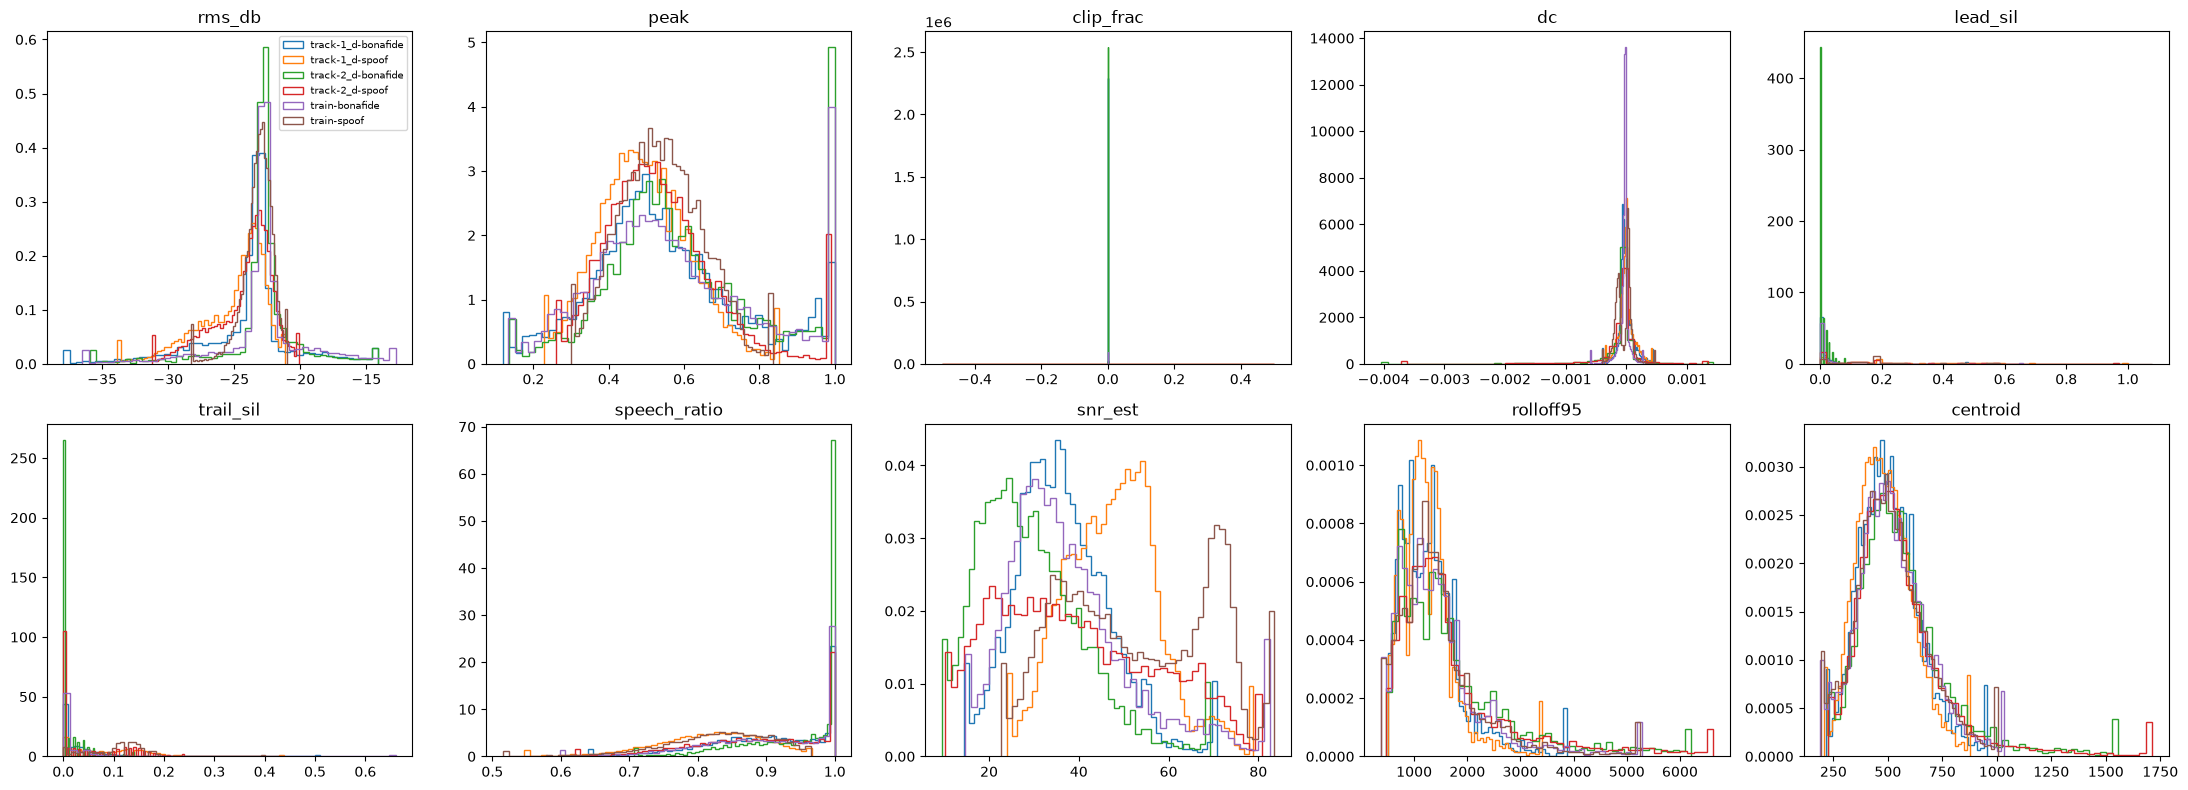

In [ ]:
COLS = ["rms_db", "peak", "clip_frac", "dc", "lead_sil", "trail_sil", "speech_ratio", "snr_est", "rolloff95", "centroid"]
print(F.groupby(["cfg", "label_name"])[COLS].median().round(3))

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for a, c in zip(axes.ravel(), COLS):
    for (s, l), d in F.groupby(["cfg", "label_name"]):
        if s in ("train", "track-1_development_test", "track-2_development_test"):
            a.hist(d[c].clip(*d[c].quantile([.01, .99])), bins=50, histtype="step", density=True, label=f"{s[:9]}-{l}")
    a.set_title(c)
axes[0, 0].legend(fontsize=7); plt.tight_layout(); plt.show()

**Result:** spoofs have leading/trailing silence and higher SNR; bona fide has almost none.

In [ ]:
D = F[F.cfg.isin(["train", "dev"])]
FEATS5 = ["rms_db", "lead_sil", "trail_sil", "speech_ratio", "snr_est"]
print(D.groupby(["dialect", "label_name"])[FEATS5].median().round(3), "\n")
print(D.groupby(["gender", "label_name"])[FEATS5].median().round(3), "\n")
rows = []
for dl, d in D.groupby("dialect"):
    if d.label.nunique() < 2: continue
    for c in FEATS5:
        e = AD.compute_eer(d.label.astype(int), d[c]); rows.append(dict(dialect=dl, feature=c, EER=round(min(e, 100 - e), 1)))
print("Single-feature EER per dialect (lower = stronger shortcut):")
print(pd.DataFrame(rows).pivot(index="feature", columns="dialect", values="EER"))

                    rms_db  lead_sil  trail_sil  speech_ratio  snr_est
dialect label_name                                                    
EGY     bonafide   -21.927      0.00       0.00         0.962   31.310
        spoof      -23.172      0.18       0.12         0.836   47.648
Gulf    bonafide   -22.830      0.00       0.00         0.901   35.895
        spoof      -23.234      0.18       0.12         0.842   49.284
MSA     bonafide   -22.704      0.00       0.00         0.855   42.597
        spoof      -22.877      0.19       0.12         0.829   63.043 

                    rms_db  lead_sil  trail_sil  speech_ratio  snr_est
gender  label_name                                                    
Female  bonafide   -22.873      0.00       0.00         0.961   30.916
        spoof      -23.170      0.17       0.12         0.858   43.066
Male    bonafide   -22.763      0.00       0.00         0.900   35.858
        spoof      -23.134      0.18       0.12         0.835   51.984
Unkn

**Result:** the silence pattern is the same in every dialect and gender.

## 6. Long-term average spectrum

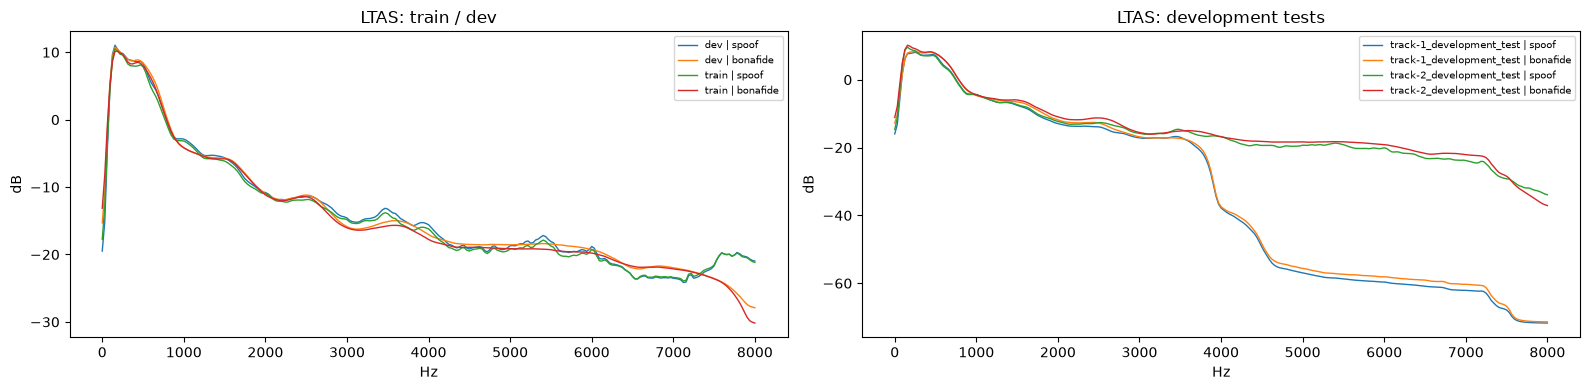

In [ ]:
f = np.fft.rfftfreq(512, 1 / 16000)
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
for (s, l), (acc, n) in sorted(LTAS.items(), key=str):
    if n == 0: continue
    a = ax[0] if s in ("train", "dev") else ax[1]
    a.plot(f, 10 * (acc / n), label=f"{s} | {'bonafide' if l == 1 else 'spoof'}", lw=1)
for a, t in zip(ax, ["train / dev", "development tests"]):
    a.set_title(f"LTAS: {t}"); a.set_xlabel("Hz"); a.set_ylabel("dB"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Result:** Track 1 dev-test is narrowband (drops above 4 kHz): a channel mismatch with train.

## 7. Shortcut audit

In [ ]:
rows = []
for s in ["train", "dev", "track-1_development_test", "track-2_development_test"]:
    d = F[F.cfg == s].dropna(subset=["label"])
    if d.label.nunique() < 2: continue
    for c in COLS + ["dur"]:
        e = AD.compute_eer(d.label.astype(int), d[c].fillna(0)); rows.append(dict(split=s, feature=c, EER=round(min(e, 100 - e), 1)))
SHORT = pd.DataFrame(rows).pivot(index="feature", columns="split", values="EER")
print(SHORT.sort_values("train"))
NUISANCE = ["rms_db", "peak", "dc", "clip_frac", "lead_sil", "trail_sil", "speech_ratio", "dur"]
low = SHORT[(SHORT[["train", "dev"]] < 40).any(axis=1)].index.tolist()
risky = [c for c in low if c in NUISANCE]
print("\nNuisance shortcuts (EER < 40%):", risky or "none")
print("Informative spectral cues (EER < 40%):", [c for c in low if c not in NUISANCE] or "none")

split          dev  track-1_development_test  track-2_development_test  train
feature                                                                      
trail_sil     15.1                      31.7                      38.0   15.0
lead_sil      15.7                      18.1                      29.2   15.2
snr_est       30.4                      28.9                      38.5   31.9
speech_ratio  33.1                      32.7                      36.4   35.7
rms_db        38.7                      37.2                      33.3   41.0
dur           46.2                      47.6                      47.8   45.9
clip_frac     48.1                      49.1                      49.3   47.3
dc            48.9                      46.0                      49.8   48.8
centroid      49.6                      46.7                      48.0   49.4
rolloff95     49.2                      48.0                      48.7   49.5
peak          48.9                      45.7                    

**Result:** silence is a strong shortcut (EER ≈ 15%); duration is not (≈ 46%).

## 8. Data quality and leakage

In [ ]:
PRIORITY = {s: i for i, s in enumerate(SPLITS)}
issues = []
q = F.assign(silent=F.peak < 50 / 32768)
for _, r in q[q.silent].iterrows(): issues.append((r.cfg, r.id, "silent", True))
for _, r in q[q.clip_frac > 0.01].iterrows(): issues.append((r.cfg, r.id, "clipped>1%", False))
for _, r in ALL[ALL.duration_sec > 30].iterrows(): issues.append((r.cfg, r.id, "duration>30s", False))
for _, r in ALL[ALL.duration_sec < 0.5].iterrows(): issues.append((r.cfg, r.id, "duration<0.5s", False))

def dup_drops(df, key, name):
    d = df.assign(prio=df.cfg.map(PRIORITY)).sort_values(["prio", "id"])
    dup = d[d.duplicated(key, keep="first")]
    for _, r in dup.iterrows(): issues.append((r.cfg, r.id, f"duplicate ({name})", True))
    return len(dup)
print("metadata sha256 duplicates dropped:", dup_drops(ALL, "sha256", "sha256"))
print("waveform md5 duplicates dropped   :", dup_drops(F, "wav_md5", "waveform"))
print("trimmed md5 duplicates dropped    :", dup_drops(F, "trim_md5", "trimmed waveform"))

ISS = pd.DataFrame(issues, columns=["cfg", "id", "reason", "drop"]).drop_duplicates(["cfg", "id", "reason"])
print(pd.crosstab(ISS.reason, ISS.cfg))

metadata sha256 duplicates dropped: 10
waveform md5 duplicates dropped   : 0
trimmed md5 duplicates dropped    : 1
cfg                           dev  track-1_development_test  track-1_test  track-2_development_test  track-2_test  train
reason                                                                                                                  
clipped>1%                      0                         0             0                         0             0      1
duplicate (sha256)              0                         0             9                         0             1      0
duplicate (trimmed waveform)    0                         0             0                         0             0      1
duration<0.5s                   0                         0             1                         0             1      0
duration>30s                    0                        77           621                        68           621      1
silent                          2     

**Result:** 20 silent clips and 1 duplicate removed from train/dev; test duplicates are flagged only.

In [ ]:
import torch
from transformers import AutoFeatureExtractor, AutoModel, AutoModelForAudioXVector
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N_PER_SPLIT = 5000
WIN = 64600

def sample_split(s, n):
    d = F[(F.cfg == s) & (F.peak >= 50 / 32768)]
    return d.sample(min(n, len(d)), random_state=SEED).reset_index(drop=True)

def embed_waves(waves, model_name, layer=None, xvector=False, bs=16):
    fe = AutoFeatureExtractor.from_pretrained(model_name)
    m = (AutoModelForAudioXVector if xvector else AutoModel).from_pretrained(model_name).to(DEVICE).eval()
    out = []
    for i in range(0, len(waves), bs):
        inp = fe([w for w in waves[i:i + bs]], sampling_rate=16000, return_tensors="pt", padding=True)
        inp = {k: v.to(DEVICE) for k, v in inp.items()}
        with torch.no_grad(), torch.autocast(DEVICE, enabled=DEVICE == "cuda"):
            e = m(**inp).embeddings if xvector else m(**inp, output_hidden_states=True).hidden_states[layer].mean(1)
        out.append(torch.nn.functional.normalize(e.float(), dim=-1).cpu())
    del m; torch.cuda.empty_cache()
    return torch.cat(out)

def first_window(r):
    return AD.crop_or_pad(AD.load_wave(f"{AUDIO_ROOT}/{r.cfg}/{r.id}.flac"), WIN, train=False)

SAMP = {s: sample_split(s, N_PER_SPLIT) for s in ["train", "dev", "track-1_development_test", "track-2_development_test"]}
EMB = {s: embed_waves([first_window(r) for _, r in d.iterrows()], "facebook/wav2vec2-xls-r-300m", layer=8) for s, d in SAMP.items()}

ctrl = SAMP["train"].head(500)
rng = np.random.RandomState(SEED)
ctrl_aug = [AD.augment(first_window(r), rng, p=1.0) for _, r in ctrl.iterrows()]
E_ctrl = embed_waves(ctrl_aug, "facebook/wav2vec2-xls-r-300m", layer=8)
pos = (E_ctrl * EMB["train"][:len(ctrl)]).sum(1).numpy()
THR = float(np.percentile(pos, 5))
print(f"positive control (same clip, degraded): median {np.median(pos):.4f}, 5th pct {THR:.4f} -> threshold")

LEAK = []
for s in ["dev", "track-1_development_test", "track-2_development_test"]:
    S = EMB[s] @ EMB["train"].T
    nn_sim, nn_idx = S.max(1)
    hit = (nn_sim > THR).numpy()
    print(f"{s}: {hit.mean() * 100:.2f}% of clips have a train clip above threshold | max sim {nn_sim.max():.4f}")
    for j in np.argsort(-nn_sim.numpy())[:5]:
        LEAK.append(dict(split=s, clip=SAMP[s].id[j], clip_label=SAMP[s].label_name[j], train=SAMP["train"].id[int(nn_idx[j])],
                         train_label=SAMP["train"].label_name[int(nn_idx[j])], sim=round(float(nn_sim[j]), 4)))
LEAK = pd.DataFrame(LEAK); print(LEAK)

Loading weights: 100%|██████████| 422/422 [00:00<00:00, 16202.97it/s]
[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 422/422 [00:00<00:00, 14514.35it/s]
[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-xls-r-300m
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.codevectors        | UNEXPECTED |  | 
quantizer.w

positive control (same clip, degraded): median 0.9408, 5th pct 0.8706 -> threshold
dev: 99.94% of clips have a train clip above threshold | max sim 0.9902
track-1_development_test: 99.96% of clips have a train clip above threshold | max sim 0.9870
track-2_development_test: 99.74% of clips have a train clip above threshold | max sim 0.9892
                       split                  clip clip_label                     train train_label     sim
0                        dev  MSA_Male_dev_3213286      spoof    MSA_Male_train_3484866       spoof  0.9902
1                        dev  MSA_Male_dev_2467183      spoof    MSA_Male_train_8416000       spoof  0.9896
2                        dev  MSA_Male_dev_5913519      spoof    MSA_Male_train_2601964       spoof  0.9893
3                        dev  MSA_Male_dev_2650413      spoof    MSA_Male_train_0433455       spoof  0.9891
4                        dev  MSA_Male_dev_2302321      spoof    MSA_Male_train_4584365       spoof  0.9891
5   track-1

**Result:** no copied audio between train and the other splits.

c:\Users\Aisha\venvs\nabra\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Aisha\.cache\huggingface\hub\models--microsoft--wavlm-base-plus-sv. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 266/266 [00:00<00:00, 10618.09it/s]
c:\Users\Aisha\venvs\nabra\Lib\site-package

calibrated speaker threshold 0.825 (speaker-verification EER on this data 2.6%)


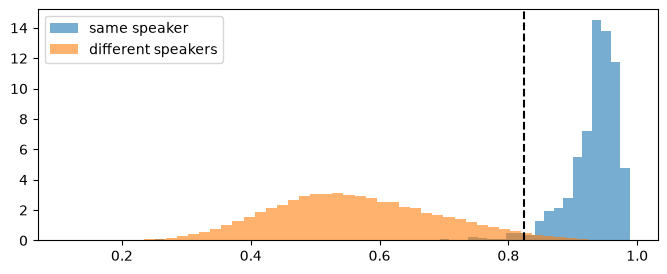

Loading weights: 100%|██████████| 266/266 [00:00<00:00, 9742.36it/s]
c:\Users\Aisha\venvs\nabra\Lib\site-packages\torch\nn\functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(
Loading weights: 100%|██████████| 266/266 [00:00<00:00, 12957.11it/s]
c:\Users\Aisha\venvs\nabra\Lib\site-packages\torch\nn\functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(
Loading weights: 100%|██████████| 266/266 [00:00<00:00, 13601.10it/s]
c:\Users\Aisha\venvs\nabra\Lib\site-packages\torch\nn\functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(
Loading weights: 100%|██████████| 266/266 [00:00<00:00, 8439.18it/s]
c:\Users\Aisha\venvs\nabra\Lib\site-packages

dev: 99.8% of clips have a same-speaker bona fide clip in train (estimate, 2,000-clip samples)
track-1_development_test: 99.6% of clips have a same-speaker bona fide clip in train (estimate, 2,000-clip samples)
track-2_development_test: 99.7% of clips have a same-speaker bona fide clip in train (estimate, 2,000-clip samples)


In [ ]:
SPK = "microsoft/wavlm-base-plus-sv"
bf = F[(F.cfg == "train") & (F.label == 1) & (F.dur >= 7) & F.gender.isin(["Male", "Female"])]
bf = bf.sample(min(800, len(bf)), random_state=SEED)
w = [AD.load_wave(f"{AUDIO_ROOT}/train/{i}.flac") for i in bf.id]
A = embed_waves([x[:3 * 16000] for x in w], SPK, xvector=True)
B = embed_waves([x[-3 * 16000:] for x in w], SPK, xvector=True)
genuine = (A * B).sum(1).numpy()
g = bf.gender.values
impostor = (A[g == "Male"] @ B[g == "Female"].T).flatten().numpy()
from sklearn.metrics import roc_curve
y = np.r_[np.ones(len(genuine)), np.zeros(len(impostor))]; sc = np.r_[genuine, impostor]
fpr, tpr, th = roc_curve(y, sc); k = np.nanargmin(np.abs(1 - tpr - fpr))
SPK_THR = float(th[k])
print(f"calibrated speaker threshold {SPK_THR:.3f} (speaker-verification EER on this data {100 * (fpr[k] + 1 - tpr[k]) / 2:.1f}%)")
plt.figure(figsize=(8, 3)); plt.hist(genuine, 50, alpha=.6, density=True, label="same speaker")
plt.hist(impostor, 50, alpha=.6, density=True, label="different speakers"); plt.axvline(SPK_THR, c="k", ls="--"); plt.legend(); plt.show()

SPKE = {s: embed_waves([first_window(r)[:3 * 16000] for _, r in d.head(2000).iterrows()], SPK, xvector=True) for s, d in SAMP.items()}
tr_bf = torch.as_tensor(SAMP["train"].head(2000).label.values == 1)
for s in ["dev", "track-1_development_test", "track-2_development_test"]:
    nn = (SPKE[s] @ SPKE["train"][tr_bf].T).max(1).values.numpy()
    print(f"{s}: {100 * (nn > SPK_THR).mean():.1f}% of clips have a same-speaker bona fide clip in train (estimate, 2,000-clip samples)")

**Result:** speakers are shared across splits by design, but every speaker has real and fake clips.

## 9. Preprocessing decisions

In [ ]:
CONFIG = dict(AD.DEFAULT_CONFIG)
CONFIG["crop_sec"] = 64600 / 16000
CONFIG["trim_silence"] = any(c in risky for c in ["lead_sil", "trail_sil", "speech_ratio"])
CONFIG["normalize"] = "rms" if any(c in risky for c in ["rms_db", "peak"]) else "none"
CONFIG["augment_p"] = 0.5
print(CONFIG)

{'crop_sec': 4.0375, 'trim_silence': True, 'normalize': 'rms', 'augment_p': 0.5}


**Result:** 4.04 s windows; silence trimming and RMS normalization on.

In [ ]:
parts = [d.sample(min(1000, len(d)), random_state=SEED) for _, d in F[F.cfg.isin(["train", "dev"])].groupby(["cfg", "label"])]
chk = pd.concat(parts)
rows = []
for _, r in chk.iterrows():
    x = AD.clean_wave(AD.load_wave(f"{AUDIO_ROOT}/{r.cfg}/{r.id}.flac"), CONFIG)
    d, _ = acoustic_features(np.clip(x * 32767, -32768, 32767).astype(np.int16))
    rows.append(dict(cfg=r.cfg, label=r.label, **d))
P = pd.DataFrame(rows); out = []
for s, d in P.groupby("cfg"):
    for c in ["lead_sil", "trail_sil", "speech_ratio", "rms_db", "snr_est"]:
        e = AD.compute_eer(d.label.astype(int), d[c]); out.append(dict(split=s, feature=c, EER=round(min(e, 100 - e), 1)))
after = pd.DataFrame(out).pivot(index="feature", columns="split", values="EER")
print(pd.concat({"before": SHORT.loc[after.index, ["dev", "train"]], "after": after}, axis=1))

             before       after      
split           dev train   dev train
feature                              
lead_sil       15.7  15.2  49.9  49.9
rms_db         38.7  41.0  48.8  47.8
snr_est        30.4  31.9  40.9  39.5
speech_ratio   33.1  35.7  41.8  41.0
trail_sil      15.1  15.0  49.9  49.8


**Result:** after preprocessing the silence and loudness shortcuts are gone (EER ≈ 50%).

## 10. Clean manifests

In [ ]:
drop = ISS[ISS["drop"]].groupby(["cfg", "id"])["reason"].apply("; ".join)
CLEAN_SPLITS = ["train", "dev"]
SUMMARY, MANIFEST = [], {}
for s in SPLITS:
    m = ALL[ALL.cfg == s][["id", "label", "dialect", "gender", "duration_sec", "sha256"]].copy()
    m["split"] = s; m["path"] = s + "/" + m["id"] + ".flac"
    m["drop_reason"] = [drop.get((s, i), "") for i in m.id]
    m["flag"] = m["drop_reason"] != ""
    m["keep"] = ~m["flag"] if s in CLEAN_SPLITS else True
    m["extracted"] = s in EXTRACT_SPLITS
    MANIFEST[s] = m
    SUMMARY.append(dict(split=s, rows=len(m), flagged=int(m.flag.sum()), dropped=int((~m.keep).sum()), kept=int(m.keep.sum()),
                        bonafide=int(m[m.keep].label.sum()), spoof=int((m[m.keep].label == 0).sum())))
print(pd.DataFrame(SUMMARY))
print("class weights [spoof, bonafide]:", AD.class_weights(MANIFEST["train"]))

                      split    rows  flagged  dropped    kept  bonafide   spoof
0                     train   22500       18       18   22482      7500   14982
1                       dev   21000        2        2   20998      6952   14046
2  track-1_development_test   16023        1        0   16023      4097   11926
3  track-2_development_test   14193        0        0   14193      3510   10683
4              track-1_test  144210        9        0  144210     36903  107307
5              track-2_test  127746        1        0  127746     31490   96256
class weights [spoof, bonafide]: [0.750300360432519, 1.4988]


**Result:** clean train 22,482 and dev 20,998 clips; test splits kept complete.

In [ ]:
OUT_DIR = "artifacts/aradf_eda"
os.makedirs(f"{OUT_DIR}/manifests", exist_ok=True)

for s, m in MANIFEST.items():
    m.to_csv(f"{OUT_DIR}/manifests/{s}.csv", index=False)
ISS.to_csv(f"{OUT_DIR}/data_issues.csv", index=False)
SHORT.to_csv(f"{OUT_DIR}/shortcut_audit.csv")
pd.DataFrame(SUMMARY).to_csv(f"{OUT_DIR}/manifest_summary.csv", index=False)

with open(f"{OUT_DIR}/preprocessing_config.json", "w", encoding="utf-8") as f:
    json.dump({
        "dataset": REPO_ID,
        "revision": REVISION,
        "audio_root": AUDIO_ROOT,
        "labels": {"1": "bona fide (real)", "0": "spoof (fake)"},
        "score_direction": "higher score = more bona fide",
        "clean_splits": CLEAN_SPLITS,
        "config": CONFIG,
    }, f, indent=2)

print("Saved to", OUT_DIR)
print("Manifests:", sorted(os.listdir(f"{OUT_DIR}/manifests")))

Saved to artifacts/aradf_eda
Manifests: ['dev.csv', 'track-1_development_test.csv', 'track-1_test.csv', 'track-2_development_test.csv', 'track-2_test.csv', 'train.csv']


## 11. Pipeline sanity check

train batch: (16, 64600) torch.float32 | labels: [1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 0]
real share over 30 balanced batches: 0.53 (expected ~0.50)
train / dev size: 22482 20998
eval batch: (12, 64600) | windows per clip: [3, 3, 3, 3] | durations: [10.1, 8.8, 8.3, 12.3]


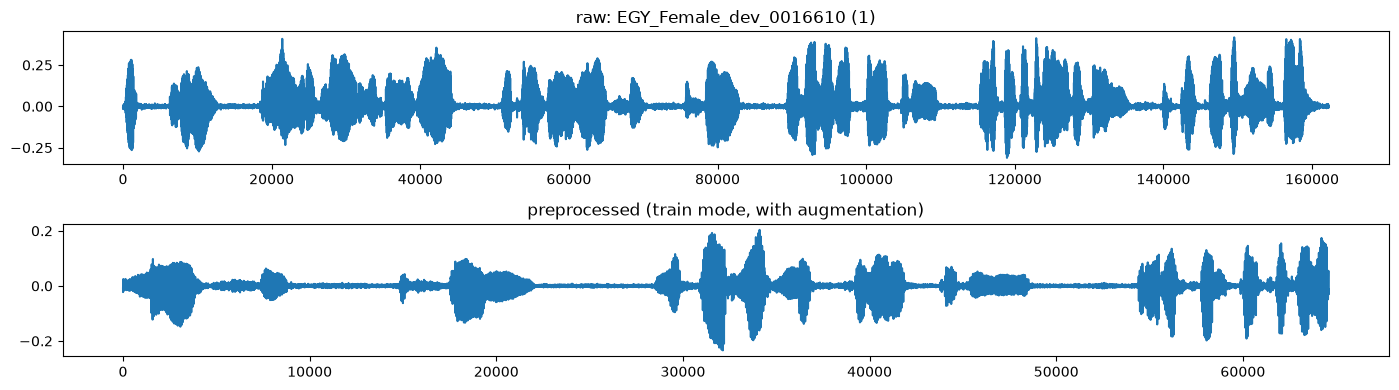

In [ ]:
import torch
ds_tr = AD.make_dataset(MANIFEST["train"], AUDIO_ROOT, CONFIG, train=True)
ds_dv = AD.make_dataset(MANIFEST["dev"], AUDIO_ROOT, CONFIG, train=False)
dl = AD.make_loader(ds_tr, batch_size=16, train=True, balanced=True, num_workers=0)
xb, yb, ib = next(iter(dl))
print("train batch:", tuple(xb.shape), xb.dtype, "| labels:", yb.tolist())
share = np.mean([next(iter(dl))[1].float().mean().item() for _ in range(30)])
print(f"real share over 30 balanced batches: {share:.2f} (expected ~0.50)")
print("train / dev size:", len(ds_tr), len(ds_dv))

dv_dl = AD.make_loader(ds_dv, batch_size=4, train=False)
wb, lb, idb, cnt = next(iter(dv_dl))
print("eval batch:", tuple(wb.shape), "| windows per clip:", cnt, "| durations:",
      [round(float(d), 1) for d in ds_dv.df.duration_sec[:4]])

from IPython.display import Audio, display
r = ds_dv.df.iloc[0]; raw = AD.load_wave(os.path.join(AUDIO_ROOT, r.path))
proc = AD.preprocess(raw, {**CONFIG, "augment_p": 0.9}, train=True)
fig, ax = plt.subplots(2, 1, figsize=(14, 4)); ax[0].plot(raw); ax[0].set_title(f"raw: {r.id} ({r.label})")
ax[1].plot(proc); ax[1].set_title("preprocessed (train mode, with augmentation)"); plt.tight_layout(); plt.show()
display(Audio(raw, rate=16000)); display(Audio(proc, rate=16000))

**Result:** batch shapes and labels are correct; evaluation covers the whole clip.

In [ ]:
print(pd.DataFrame(SUMMARY).to_string(index=False))
print("\npreprocessing config:", CONFIG)
print("dropped clips by reason:"); print(ISS[ISS["drop"]].groupby(["reason", "cfg"]).size().unstack(fill_value=0))

                   split   rows  flagged  dropped   kept  bonafide  spoof
                   train  22500       18       18  22482      7500  14982
                     dev  21000        2        2  20998      6952  14046
track-1_development_test  16023        1        0  16023      4097  11926
track-2_development_test  14193        0        0  14193      3510  10683
            track-1_test 144210        9        0 144210     36903 107307
            track-2_test 127746        1        0 127746     31490  96256

preprocessing config: {'crop_sec': 4.0375, 'trim_silence': True, 'normalize': 'rms', 'augment_p': 0.5}
dropped clips by reason:
cfg                           dev  track-1_development_test  track-1_test  track-2_test  train
reason                                                                                        
duplicate (sha256)              0                         0             9             1      0
duplicate (trimmed waveform)    0                         0         

**Result:** data ready for training.

## 12. Model training: Wavelet Prompt Tuning (WPT)
One run per model: set `MODEL` in 12.2.

In [4]:
import sys, os, json, time, math, platform, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers==5.18.0",
                    "huggingface-hub==1.33.0", "codecarbon==3.3.2", "soundfile"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")

import numpy as np, pandas as pd, torch, transformers, huggingface_hub
assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > L4"
if transformers.__version__ != "5.18.0":
    print("WARNING: transformers", transformers.__version__, "is loaded. Restart the session (Runtime > Restart session) and run 12.1 again.")
GPU_NAME = torch.cuda.get_device_name(0)
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 2**30
print("Python", platform.python_version(), "| torch", torch.__version__, "| transformers", transformers.__version__,
      "| huggingface_hub", huggingface_hub.__version__)
print(f"GPU: {GPU_NAME} | {GPU_GB:.1f} GB | bf16: {torch.cuda.is_bf16_supported()}")

c:\Users\Aisha\venvs\nabra\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Python 3.13.5 | torch 2.14.1+cu126 | transformers 5.18.0 | huggingface_hub 1.33.0
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU | 6.0 GB | bf16: True


In [5]:
MODEL = "wavlm_large"
QUICK_TEST = False

HF_MODELS = {"xlsr300m": "facebook/wav2vec2-xls-r-300m", "wavlm_large": "microsoft/wavlm-large"}
REPO_ID = "ArabicSpeech/ArA-DF-2026"
REVISION = "2b1f042dc166b1d372841cb0d7110661ea5b2a93"

if IN_COLAB:
    PROJECT_ROOT = "/content/drive/MyDrive/nabra"
    AUDIO_ROOT = "/content/aradf_audio"
    RUNS_ROOT = os.path.join(PROJECT_ROOT, "runs")
else:
    PROJECT_ROOT = r"C:\Users\Aisha\OneDrive\سطح المكتب\vss\Grad"
    AUDIO_ROOT = r"C:\Users\Aisha\nabra_data\aradf_audio"
    RUNS_ROOT = r"C:\Users\Aisha\nabra_runs"
ART_DIR = os.path.join(PROJECT_ROOT, "artifacts", "aradf_eda")
RUN_DIR = os.path.join(RUNS_ROOT, f"{MODEL}__wpt" + ("__quicktest" if QUICK_TEST else ""))

CFG = dict(
    method="wavelet_prompt_tuning", model=MODEL, hf_model=HF_MODELS[MODEL], dataset=REPO_ID, revision=REVISION,
    seed=42,
    sample_rate=16000, max_len=64600,
    trim_silence=True, rms_dbfs=-23.0,
    augmentation=None,
    trainable="prompts + wavelet projection + AASIST + output layer; SSL encoder frozen",
    n_prompts=6, n_wavelet_prompts=4,
    wavelet="Haar, 1 level, along the feature dimension; Proj = Linear(d, d) shared by all layers",
    prompt_init="xavier uniform, bound sqrt(6 / 2d)",
    prompt_dropout=0.1,
    backbone_mode="eval",
    optimizer="adamw", betas=(0.9, 0.999), lr=1e-4, weight_decay=1e-4,
    warmup_steps=500, schedule="linear warm-up then cosine decay, per optimizer step",
    batch_size=8, max_epochs=8,
    monitor="dev EER, min (best epoch kept; no early stopping)",
    class_weights=[0.3, 0.7],
    aasist=dict(filts=[70, [1, 32], [32, 32], [32, 64], [64, 64]], gat_dims=[64, 32],
                pool_ratios=[0.5, 0.7, 0.5, 0.5], temperatures=[2.0, 2.0, 100.0, 100.0]),
    score="logit_bonafide - logit_spoof",
    dev_eval_in_training="one centre crop of 64,600 samples",
    final_eval="whole clip, consecutive 64,600-sample windows, mean score",
    precision="bf16 autocast",
    gradient_checkpointing=False,
    spec_augment=False,
)
if QUICK_TEST:
    CFG["max_epochs"] = 1
EVAL_SPLITS = ["dev"] if QUICK_TEST else ["dev", "track-1_test"]
os.makedirs(RUN_DIR, exist_ok=True)

import random
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.benchmark = False
set_seed(CFG["seed"])
print("model:", CFG["hf_model"], "| run folder:", RUN_DIR)

model: microsoft/wavlm-large | run folder: C:\Users\Aisha\nabra_runs\wavlm_large__wpt


In [6]:
import tarfile
from huggingface_hub import HfApi, hf_hub_download
HF_TOKEN = os.environ.get("HF_TOKEN")

assert os.path.isdir(os.path.join(ART_DIR, "manifests")), f"No manifests in {ART_DIR}. Run section 10b or add the shared folder to My Drive."
with open(os.path.join(ART_DIR, "preprocessing_config.json"), encoding="utf-8") as f:
    PREP = json.load(f)
assert PREP["revision"] == REVISION, "Manifests were made from a different dataset version"

def load_manifest(split):
    m = pd.read_csv(os.path.join(ART_DIR, "manifests", f"{split}.csv"))
    return m[m["keep"].astype(bool)].reset_index(drop=True)

MAN = {s: load_manifest(s) for s in ["train", "dev", "track-1_test"]}
for s, m in MAN.items():
    print(f"{s:13s} {len(m):7,d} clips | bona fide {int(m.label.sum()):6,d} | spoof {int((m.label == 0).sum()):7,d}")
assert (len(MAN["train"]), len(MAN["dev"]), len(MAN["track-1_test"])) == (22482, 20998, 144210)
if QUICK_TEST:
    for s in ["train", "dev"]:
        MAN[s] = MAN[s].sample(64, random_state=CFG["seed"]).reset_index(drop=True)

def extract_split(split, ids):
    os.makedirs(os.path.join(AUDIO_ROOT, split), exist_ok=True)
    want = {i for i in ids if not os.path.exists(os.path.join(AUDIO_ROOT, split, f"{i}.flac"))}
    if not want:
        print(f"{split}: all {len(ids):,} clips already on disk"); return
    files = HfApi().list_repo_files(REPO_ID, repo_type="dataset", revision=REVISION, token=HF_TOKEN)
    tars = sorted(f for f in files if f.startswith(f"data/{split}/") and f.endswith(".tar"))
    t0 = time.time()
    for t in tars:
        local = hf_hub_download(REPO_ID, t, repo_type="dataset", revision=REVISION, token=HF_TOKEN)
        with tarfile.open(local) as tf:
            for mem in tf:
                if mem.isfile() and mem.name.endswith(".flac"):
                    cid = os.path.basename(mem.name)[:-5]
                    if cid in want:
                        with open(os.path.join(AUDIO_ROOT, split, f"{cid}.flac"), "wb") as f:
                            f.write(tf.extractfile(mem).read())
        print(f"  {t} | {time.time() - t0:.0f}s")
    missing = [i for i in ids if not os.path.exists(os.path.join(AUDIO_ROOT, split, f"{i}.flac"))]
    assert not missing, f"{split}: {len(missing)} clips missing after extraction"
    print(f"{split}: {len(ids):,} clips ready")

for s in ["train", "dev"]:
    extract_split(s, MAN[s]["id"].tolist())

train          22,482 clips | bona fide  7,500 | spoof  14,982
dev            20,998 clips | bona fide  6,952 | spoof  14,046
track-1_test  144,210 clips | bona fide 36,903 | spoof 107,307
train: all 22,482 clips already on disk
dev: all 20,998 clips already on disk


In [7]:
import soundfile as sf
SR, N = CFG["sample_rate"], CFG["max_len"]

def load_wave(path):
    x, sr = sf.read(path, dtype="float32", always_2d=False)
    if x.ndim > 1: x = x.mean(1)
    assert sr == SR, f"{path}: sr={sr}"
    return x

def trim_silence(x, top_db=40.0, frame=400, hop=160):
    if len(x) < frame: return x
    nf = 1 + (len(x) - frame) // hop
    idx = np.arange(frame)[None, :] + hop * np.arange(nf)[:, None]
    e = 10 * np.log10((x[idx] ** 2).mean(1) + 1e-10)
    v = np.flatnonzero(e > e.max() - top_db)
    return x[v[0] * hop: v[-1] * hop + frame] if len(v) else x

def rms_normalize(x, target_dbfs=-23.0):
    rms = np.sqrt(np.mean(x ** 2) + 1e-12)
    return np.clip(x * (10 ** (target_dbfs / 20) / rms), -1, 1).astype(np.float32)

def clean_wave(x):
    if CFG["trim_silence"]: x = trim_silence(x)
    return rms_normalize(x, CFG["rms_dbfs"])

def crop_or_pad(x, n, mode, rng=None):
    if len(x) == 0: return np.zeros(n, np.float32)
    if len(x) < n: x = np.tile(x, int(np.ceil(n / len(x))))
    if len(x) == n: return x
    if mode == "random": start = rng.randint(0, len(x) - n + 1)
    elif mode == "center": start = (len(x) - n) // 2
    else: start = 0
    return x[start:start + n]

def make_windows(x, n):
    if len(x) <= n: return crop_or_pad(x, n, "start")[None, :]
    starts = list(range(0, len(x) - n + 1, n))
    if starts[-1] + n < len(x): starts.append(len(x) - n)
    return np.stack([x[s:s + n] for s in starts])

class AraDF(torch.utils.data.Dataset):
    def __init__(self, manifest, mode):
        self.ids = manifest["id"].tolist(); self.labels = manifest["label"].astype(int).tolist()
        self.paths = manifest["path"].tolist(); self.mode = mode
        self.rng = np.random.RandomState(CFG["seed"])
    def __len__(self): return len(self.ids)
    def __getitem__(self, i):
        x = clean_wave(load_wave(os.path.join(AUDIO_ROOT, self.paths[i])))
        w = make_windows(x, N) if self.mode == "windows" else crop_or_pad(x, N, self.mode, self.rng)[None, :]
        return torch.from_numpy(np.ascontiguousarray(w, dtype=np.float32)), self.labels[i], self.ids[i]

def seed_worker(worker_id):
    info = torch.utils.data.get_worker_info()
    info.dataset.rng = np.random.RandomState(torch.initial_seed() % 2**32)

def collate(batch):
    waves = torch.cat([b[0] for b in batch])
    return waves, torch.tensor([b[1] for b in batch]), [b[2] for b in batch], [b[0].shape[0] for b in batch]

NUM_WORKERS = min(8, os.cpu_count() or 1) if IN_COLAB else 0
def make_loader(ds, batch_size, shuffle, epoch=0):
    g = torch.Generator(); g.manual_seed(CFG["seed"] + epoch)
    if NUM_WORKERS == 0: ds.rng = np.random.RandomState(CFG["seed"] + epoch)
    return torch.utils.data.DataLoader(ds, batch_size=batch_size, shuffle=shuffle, drop_last=shuffle,
                                       num_workers=NUM_WORKERS, worker_init_fn=seed_worker if NUM_WORKERS else None,
                                       generator=g, collate_fn=collate, pin_memory=True)

ds_train, ds_dev = AraDF(MAN["train"], "random"), AraDF(MAN["dev"], "center")
xb, yb, _, _ = next(iter(make_loader(ds_train, CFG["batch_size"], shuffle=True)))
print("train batch:", tuple(xb.shape), "| bona fide share:", round(float(yb.float().mean()), 2))
xd, yd, _, cd = next(iter(make_loader(ds_dev, 8, shuffle=False)))
print("dev batch (centre crop):", tuple(xd.shape), "| windows per clip:", cd)
xw, _, _, cw = next(iter(make_loader(AraDF(MAN["dev"], "windows"), 4, shuffle=False)))
print("final-eval batch (whole clip):", tuple(xw.shape), "| windows per clip:", cw)
del xb, yb, xd, yd, xw

train batch: (8, 64600) | bona fide share: 0.25
dev batch (centre crop): (8, 64600) | windows per clip: [1, 1, 1, 1, 1, 1, 1, 1]
final-eval batch (whole clip): (12, 64600) | windows per clip: [3, 3, 3, 3]


In [8]:
# Adapted from DeepFense (Apache License 2.0):
#   https://github.com/Yaselley/deepfense-framework  deepfense/models/backends/aasist.py
# Change: no DeepFense registry / BaseBackend; layers and computations are unchanged.
import random
from typing import Union
import torch.nn as nn
import torch.nn.functional as F
from torch import Tensor

class GraphAttentionLayer(nn.Module):
    def __init__(self, in_dim, out_dim, **kwargs):
        super().__init__()

        self.att_proj = nn.Linear(in_dim, out_dim)
        self.att_weight = self._init_new_params(out_dim, 1)

        self.proj_with_att = nn.Linear(in_dim, out_dim)
        self.proj_without_att = nn.Linear(in_dim, out_dim)

        self.bn = nn.BatchNorm1d(out_dim)

        self.input_drop = nn.Dropout(p=0.2)

        self.act = nn.SELU(inplace=True)

        self.temp = 1.0
        if "temperature" in kwargs:
            self.temp = kwargs["temperature"]

    def forward(self, x):
        x = self.input_drop(x)

        att_map = self._derive_att_map(x)

        x = self._project(x, att_map)

        x = self._apply_BN(x)
        x = self.act(x)
        return x

    def _pairwise_mul_nodes(self, x):

        nb_nodes = x.size(1)
        x = x.unsqueeze(2).expand(-1, -1, nb_nodes, -1)
        x_mirror = x.transpose(1, 2)

        return x * x_mirror

    def _derive_att_map(self, x):
        att_map = self._pairwise_mul_nodes(x)
        att_map = torch.tanh(self.att_proj(att_map))
        att_map = torch.matmul(att_map, self.att_weight)

        att_map = att_map / self.temp

        att_map = F.softmax(att_map, dim=-2)

        return att_map

    def _project(self, x, att_map):
        x1 = self.proj_with_att(torch.matmul(att_map.squeeze(-1), x))
        x2 = self.proj_without_att(x)

        return x1 + x2

    def _apply_BN(self, x):
        org_size = x.size()
        x = x.view(-1, org_size[-1])
        x = self.bn(x)
        x = x.view(org_size)

        return x

    def _init_new_params(self, *size):
        out = nn.Parameter(torch.FloatTensor(*size))
        nn.init.xavier_normal_(out)
        return out

class HtrgGraphAttentionLayer(nn.Module):
    def __init__(self, in_dim, out_dim, **kwargs):
        super().__init__()

        self.proj_type1 = nn.Linear(in_dim, in_dim)
        self.proj_type2 = nn.Linear(in_dim, in_dim)

        self.att_proj = nn.Linear(in_dim, out_dim)
        self.att_projM = nn.Linear(in_dim, out_dim)

        self.att_weight11 = self._init_new_params(out_dim, 1)
        self.att_weight22 = self._init_new_params(out_dim, 1)
        self.att_weight12 = self._init_new_params(out_dim, 1)
        self.att_weightM = self._init_new_params(out_dim, 1)

        self.proj_with_att = nn.Linear(in_dim, out_dim)
        self.proj_without_att = nn.Linear(in_dim, out_dim)

        self.proj_with_attM = nn.Linear(in_dim, out_dim)
        self.proj_without_attM = nn.Linear(in_dim, out_dim)

        self.bn = nn.BatchNorm1d(out_dim)

        self.input_drop = nn.Dropout(p=0.2)

        self.act = nn.SELU(inplace=True)

        self.temp = 1.0
        if "temperature" in kwargs:
            self.temp = kwargs["temperature"]

    def forward(self, x1, x2, master=None):
        num_type1 = x1.size(1)
        num_type2 = x2.size(1)

        x1 = self.proj_type1(x1)
        x2 = self.proj_type2(x2)

        x = torch.cat([x1, x2], dim=1)

        if master is None:
            master = torch.mean(x, dim=1, keepdim=True)

        x = self.input_drop(x)

        att_map = self._derive_att_map(x, num_type1, num_type2)

        master = self._update_master(x, master)

        x = self._project(x, att_map)

        x = self._apply_BN(x)
        x = self.act(x)

        x1 = x.narrow(1, 0, num_type1)
        x2 = x.narrow(1, num_type1, num_type2)

        return x1, x2, master

    def _update_master(self, x, master):
        att_map = self._derive_att_map_master(x, master)
        master = self._project_master(x, master, att_map)

        return master

    def _pairwise_mul_nodes(self, x):

        nb_nodes = x.size(1)
        x = x.unsqueeze(2).expand(-1, -1, nb_nodes, -1)
        x_mirror = x.transpose(1, 2)

        return x * x_mirror

    def _derive_att_map_master(self, x, master):
        att_map = x * master
        att_map = torch.tanh(self.att_projM(att_map))

        att_map = torch.matmul(att_map, self.att_weightM)

        att_map = att_map / self.temp

        att_map = F.softmax(att_map, dim=-2)

        return att_map

    def _derive_att_map(self, x, num_type1, num_type2):
        att_map = self._pairwise_mul_nodes(x)
        att_map = torch.tanh(self.att_proj(att_map))

        att_board = torch.zeros_like(att_map[:, :, :, 0]).unsqueeze(-1)

        att_board[:, :num_type1, :num_type1, :] = torch.matmul(
            att_map[:, :num_type1, :num_type1, :], self.att_weight11
        )
        att_board[:, num_type1:, num_type1:, :] = torch.matmul(
            att_map[:, num_type1:, num_type1:, :], self.att_weight22
        )
        att_board[:, :num_type1, num_type1:, :] = torch.matmul(
            att_map[:, :num_type1, num_type1:, :], self.att_weight12
        )
        att_board[:, num_type1:, :num_type1, :] = torch.matmul(
            att_map[:, num_type1:, :num_type1, :], self.att_weight12
        )

        att_map = att_board

        att_map = att_map / self.temp

        att_map = F.softmax(att_map, dim=-2)

        return att_map

    def _project(self, x, att_map):
        x1 = self.proj_with_att(torch.matmul(att_map.squeeze(-1), x))
        x2 = self.proj_without_att(x)

        return x1 + x2

    def _project_master(self, x, master, att_map):
        x1 = self.proj_with_attM(torch.matmul(att_map.squeeze(-1).unsqueeze(1), x))
        x2 = self.proj_without_attM(master)

        return x1 + x2

    def _apply_BN(self, x):
        org_size = x.size()
        x = x.view(-1, org_size[-1])
        x = self.bn(x)
        x = x.view(org_size)

        return x

    def _init_new_params(self, *size):
        out = nn.Parameter(torch.FloatTensor(*size))
        nn.init.xavier_normal_(out)
        return out

class GraphPool(nn.Module):
    def __init__(self, k: float, in_dim: int, p: Union[float, int]):
        super().__init__()
        self.k = k
        self.sigmoid = nn.Sigmoid()
        self.proj = nn.Linear(in_dim, 1)
        self.drop = nn.Dropout(p=p) if p > 0 else nn.Identity()
        self.in_dim = in_dim

    def forward(self, h):
        Z = self.drop(h)
        weights = self.proj(Z)
        scores = self.sigmoid(weights)
        new_h = self.top_k_graph(scores, h, self.k)

        return new_h

    def top_k_graph(self, scores, h, k):
        _, n_nodes, n_feat = h.size()
        n_nodes = max(int(n_nodes * k), 1)
        _, idx = torch.topk(scores, n_nodes, dim=1)
        idx = idx.expand(-1, -1, n_feat)

        h = h * scores
        h = torch.gather(h, 1, idx)

        return h

class Residual_block(nn.Module):
    def __init__(self, nb_filts, pool=(1, 3), first=False):
        super().__init__()
        self.first = first

        if not self.first:
            self.bn1 = nn.BatchNorm2d(num_features=nb_filts[0])
        self.conv1 = nn.Conv2d(
            in_channels=nb_filts[0],
            out_channels=nb_filts[1],
            kernel_size=(2, 3),
            padding=(1, 1),
            stride=1,
        )
        self.selu = nn.SELU(inplace=True)

        self.bn2 = nn.BatchNorm2d(num_features=nb_filts[1])
        self.conv2 = nn.Conv2d(
            in_channels=nb_filts[1],
            out_channels=nb_filts[1],
            kernel_size=(2, 3),
            padding=(0, 1),
            stride=1,
        )

        if nb_filts[0] != nb_filts[1]:
            self.downsample = True
            self.conv_downsample = nn.Conv2d(
                in_channels=nb_filts[0],
                out_channels=nb_filts[1],
                padding=(0, 1),
                kernel_size=(1, 3),
                stride=1,
            )

        else:
            self.downsample = False
        self.mp = nn.MaxPool2d(pool)

    def forward(self, x):
        identity = x
        if not self.first:
            out = self.bn1(x)
            out = self.selu(out)
        else:
            out = x
        out = self.conv1(x)
        out = self.bn2(out)
        out = self.selu(out)
        out = self.conv2(out)

        if self.downsample:
            identity = self.conv_downsample(identity)

        out += identity
        return out

class AASIST(nn.Module):
    def __init__(self, input_dim=1024, filts=(70, [1, 32], [32, 32], [32, 64], [64, 64]), gat_dims=(64, 32),
                 pool_ratios=(0.5, 0.7, 0.5, 0.5), temperatures=(2.0, 2.0, 100.0, 100.0)):
        super().__init__()
        self.LL = nn.Linear(input_dim, 128)

        self.first_bn = nn.BatchNorm2d(num_features=1)
        self.first_bn1 = nn.BatchNorm2d(num_features=64)
        self.drop = nn.Dropout(0.5, inplace=True)
        self.drop_way = nn.Dropout(0.2, inplace=True)
        self.selu = nn.SELU(inplace=True)

        self.encoder = nn.Sequential(
            nn.Sequential(Residual_block(nb_filts=filts[1], first=True)),
            nn.Sequential(Residual_block(nb_filts=filts[2])),
            nn.Sequential(Residual_block(nb_filts=filts[3])),
            nn.Sequential(Residual_block(nb_filts=filts[4])),
            nn.Sequential(Residual_block(nb_filts=filts[4])),
            nn.Sequential(Residual_block(nb_filts=filts[4])),
        )

        self.attention = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=(1, 1)),
            nn.SELU(inplace=True),
            nn.BatchNorm2d(128),
            nn.Conv2d(128, 64, kernel_size=(1, 1)),
        )
        self.pos_S = nn.Parameter(torch.randn(1, 42, filts[-1][-1]))

        self.master1 = nn.Parameter(torch.randn(1, 1, gat_dims[0]))
        self.master2 = nn.Parameter(torch.randn(1, 1, gat_dims[0]))

        self.GAT_layer_S = GraphAttentionLayer(
            filts[-1][-1], gat_dims[0], temperature=temperatures[0]
        )
        self.GAT_layer_T = GraphAttentionLayer(
            filts[-1][-1], gat_dims[0], temperature=temperatures[1]
        )
        self.HtrgGAT_layer_ST11 = HtrgGraphAttentionLayer(
            gat_dims[0], gat_dims[1], temperature=temperatures[2]
        )
        self.HtrgGAT_layer_ST12 = HtrgGraphAttentionLayer(
            gat_dims[1], gat_dims[1], temperature=temperatures[2]
        )
        self.HtrgGAT_layer_ST21 = HtrgGraphAttentionLayer(
            gat_dims[0], gat_dims[1], temperature=temperatures[2]
        )
        self.HtrgGAT_layer_ST22 = HtrgGraphAttentionLayer(
            gat_dims[1], gat_dims[1], temperature=temperatures[2]
        )

        self.pool_S = GraphPool(pool_ratios[0], gat_dims[0], 0.3)
        self.pool_T = GraphPool(pool_ratios[1], gat_dims[0], 0.3)
        self.pool_hS1 = GraphPool(pool_ratios[2], gat_dims[1], 0.3)
        self.pool_hT1 = GraphPool(pool_ratios[2], gat_dims[1], 0.3)

        self.pool_hS2 = GraphPool(pool_ratios[2], gat_dims[1], 0.3)
        self.pool_hT2 = GraphPool(pool_ratios[2], gat_dims[1], 0.3)

    def forward(self, x):
        x = self.LL(x)
        x = x.transpose(1, 2)
        x = x.unsqueeze(dim=1)
        x = F.max_pool2d(x, (3, 3))
        x = self.first_bn(x)
        x = self.selu(x)

        x = self.encoder(x)
        x = self.first_bn1(x)
        x = self.selu(x)

        w = self.attention(x)

        w1 = F.softmax(w, dim=-1)
        m = torch.sum(x * w1, dim=-1)
        e_S = m.transpose(1, 2) + self.pos_S

        gat_S = self.GAT_layer_S(e_S)
        out_S = self.pool_S(gat_S)

        w2 = F.softmax(w, dim=-2)
        m1 = torch.sum(x * w2, dim=-2)

        e_T = m1.transpose(1, 2)

        gat_T = self.GAT_layer_T(e_T)
        out_T = self.pool_T(gat_T)

        master1 = self.master1.expand(x.size(0), -1, -1)
        master2 = self.master2.expand(x.size(0), -1, -1)

        out_T1, out_S1, master1 = self.HtrgGAT_layer_ST11(
            out_T, out_S, master=self.master1
        )

        out_S1 = self.pool_hS1(out_S1)
        out_T1 = self.pool_hT1(out_T1)

        out_T_aug, out_S_aug, master_aug = self.HtrgGAT_layer_ST12(
            out_T1, out_S1, master=master1
        )
        out_T1 = out_T1 + out_T_aug
        out_S1 = out_S1 + out_S_aug
        master1 = master1 + master_aug

        out_T2, out_S2, master2 = self.HtrgGAT_layer_ST21(
            out_T, out_S, master=self.master2
        )
        out_S2 = self.pool_hS2(out_S2)
        out_T2 = self.pool_hT2(out_T2)

        out_T_aug, out_S_aug, master_aug = self.HtrgGAT_layer_ST22(
            out_T2, out_S2, master=master2
        )
        out_T2 = out_T2 + out_T_aug
        out_S2 = out_S2 + out_S_aug
        master2 = master2 + master_aug

        out_T1 = self.drop_way(out_T1)
        out_T2 = self.drop_way(out_T2)
        out_S1 = self.drop_way(out_S1)
        out_S2 = self.drop_way(out_S2)
        master1 = self.drop_way(master1)
        master2 = self.drop_way(master2)

        out_T = torch.max(out_T1, out_T2)
        out_S = torch.max(out_S1, out_S2)
        master = torch.max(master1, master2)

        T_max, _ = torch.max(torch.abs(out_T), dim=1)
        T_avg = torch.mean(out_T, dim=1)

        S_max, _ = torch.max(torch.abs(out_S), dim=1)
        S_avg = torch.mean(out_S, dim=1)

        last_hidden = torch.cat([T_max, T_avg, S_max, S_avg, master.squeeze(1)], dim=1)

        last_hidden = self.drop(last_hidden)

        return last_hidden

_t = AASIST(input_dim=1024, **CFG['aasist']).eval()
with torch.no_grad():
    _o = _t(torch.randn(2, 201, 1024))
print('AASIST output:', tuple(_o.shape), '(expected (2, 160)) | parameters:', sum(p.numel() for p in _t.parameters()))
assert tuple(_o.shape) == (2, 160)
del _t, _o

AASIST output: (2, 160) (expected (2, 160)) | parameters: 446920


In [9]:
from transformers import AutoConfig, AutoModel, AutoFeatureExtractor
from torch.utils.checkpoint import checkpoint

def haar_dwt(q):
    even, odd = q[..., 0::2], q[..., 1::2]
    return (even + odd) / math.sqrt(2), (even - odd) / math.sqrt(2)

class WPTEncoder(nn.Module):
    def __init__(self, hf_name):
        super().__init__()
        conf = AutoConfig.from_pretrained(hf_name)
        conf.apply_spec_augment = CFG["spec_augment"]
        self.ssl = AutoModel.from_pretrained(hf_name, config=conf)
        self.ssl.requires_grad_(False)
        self.is_wavlm = conf.model_type == "wavlm"
        self.pre_ln = bool(conf.do_stable_layer_norm)
        L, d = conf.num_hidden_layers, conf.hidden_size
        assert d % 2 == 0
        self.n_p, self.n_w = CFG["n_prompts"], CFG["n_wavelet_prompts"]
        bound = math.sqrt(6.0 / (2 * d))
        self.P = nn.Parameter(torch.empty(L, self.n_p, d).uniform_(-bound, bound))
        self.Q = nn.Parameter(torch.empty(L, self.n_w, d).uniform_(-bound, bound))
        self.proj = nn.Linear(d, d)
        self.drop = nn.Dropout(CFG["prompt_dropout"])

    def train(self, mode=True):
        super().train(mode)
        self.ssl.eval()
        return self

    def forward(self, wav, use_prompts=True):
        B, enc = wav.shape[0], self.ssl.encoder
        with torch.no_grad():
            f = self.ssl.feature_extractor(wav).transpose(1, 2)
            h, _ = self.ssl.feature_projection(f)
            h = h + enc.pos_conv_embed(h)
            if not self.pre_ln:
                h = enc.layer_norm(h)
            h = enc.dropout(h)
        n = self.n_w + self.n_p if use_prompts else 0
        bias = None
        for i, layer in enumerate(enc.layers):
            if use_prompts:
                A, D = haar_dwt(self.Q[i])
                wp = self.drop(self.proj(torch.cat([A, D], -1)).expand(B, -1, -1))
                p = self.drop(self.P[i].expand(B, -1, -1))
                x = torch.cat([wp.to(h.dtype), p.to(h.dtype), h], 1)
            else:
                x = h
            if self.is_wavlm:
                run = lambda x, bias, layer=layer, i=i: layer(x, position_bias=bias, index=i)
            else:
                run = lambda x, bias, layer=layer: (layer(x), None)
            if CFG["gradient_checkpointing"] and self.training:
                x, bias = checkpoint(run, x, bias, use_reentrant=False)
            else:
                x, bias = run(x, bias)
            h = x[:, n:]
        if self.pre_ln:
            h = enc.layer_norm(h)
        return h

class Detector(nn.Module):
    def __init__(self, hf_name):
        super().__init__()
        self.enc = WPTEncoder(hf_name)
        self.do_normalize = bool(getattr(AutoFeatureExtractor.from_pretrained(hf_name), "do_normalize", False))
        self.backend = AASIST(input_dim=self.enc.ssl.config.hidden_size, **CFG["aasist"])
        self.fc = nn.Linear(5 * CFG["aasist"]["gat_dims"][1], 2)

    def forward(self, wav):
        if self.do_normalize:
            with torch.autocast("cuda", enabled=False):
                wav = wav.float()
                wav = (wav - wav.mean(1, keepdim=True)) / torch.sqrt(wav.var(1, keepdim=True, unbiased=False) + 1e-7)
        return self.fc(self.backend(self.enc(wav)))

def score_of(logits):
    return (logits[:, 1] - logits[:, 0]).float()

set_seed(CFG["seed"])
model = Detector(CFG["hf_model"]).cuda()
n_all = sum(p.numel() for p in model.parameters()); n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
n_prompt = model.enc.P.numel() + model.enc.Q.numel() + sum(p.numel() for p in model.enc.proj.parameters())
print(f"parameters: {n_all / 1e6:.1f}M | trainable: {n_train / 1e6:.2f}M ({100 * n_train / n_all:.2f}%) "
      f"| prompts + projection: {n_prompt / 1e6:.2f}M | input normalization: {model.do_normalize}")
assert all(not p.requires_grad for p in model.enc.ssl.parameters())

model.eval()
with torch.no_grad():
    w = 0.05 * torch.randn(2, CFG["max_len"], device="cuda")
    ref = model.enc.ssl(w).last_hidden_state
    diff = (model.enc(w, use_prompts=False) - ref).abs().max().item()
print(f"layer loop vs Hugging Face forward (no prompts): max difference {diff:.2e}")
assert diff < 1e-3
del w, ref

Loading weights: 100%|██████████| 488/488 [00:00<00:00, 26619.07it/s]


parameters: 317.2M | trainable: 1.74M (0.55%) | prompts + projection: 1.30M | input normalization: True
layer loop vs Hugging Face forward (no prompts): max difference 0.00e+00


In [ ]:
AMP = dict(device_type="cuda", dtype=torch.bfloat16)
W = torch.tensor(CFG["class_weights"], device="cuda")
crit_sum = nn.CrossEntropyLoss(weight=W, reduction="sum")
TRAINABLE = [p for p in model.parameters() if p.requires_grad]

state0 = {k: v.detach().clone() for k, v in model.state_dict().items()}
def probe(micro):
    opt = torch.optim.AdamW(TRAINABLE, lr=CFG["lr"], betas=CFG["betas"], weight_decay=CFG["weight_decay"])
    x = 0.05 * torch.randn(micro, N, device="cuda"); y = torch.randint(0, 2, (micro,), device="cuda")
    model.train(); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize(); t = time.time()
    with torch.autocast(**AMP):
        loss = crit_sum(model(x), y) / W[y].sum()
    loss.backward(); opt.step(); opt.zero_grad(set_to_none=True); torch.cuda.synchronize()
    dt, mem = time.time() - t, torch.cuda.max_memory_allocated() / 2**30
    del opt, x, y, loss
    return dt, mem

MICRO = None
for micro in [8, 4, 2, 1]:
    try:
        probe(micro); dt, mem = probe(micro)
        if mem < 0.9 * GPU_GB:
            MICRO = micro; break
    except torch.OutOfMemoryError:
        pass
    model.zero_grad(set_to_none=True); torch.cuda.empty_cache()
model.load_state_dict(state0); model.zero_grad(set_to_none=True); del state0; torch.cuda.empty_cache()
assert MICRO, "Not enough GPU memory even for one clip"
ACCUM = CFG["batch_size"] // MICRO
steps = len(MAN["train"]) // CFG["batch_size"]
print(f"micro-batch {MICRO} x accumulation {ACCUM} = batch {MICRO * ACCUM} | peak memory {mem:.1f} / {GPU_GB:.1f} GB")
print(f"{dt:.2f}s per micro-batch -> about {steps * ACCUM * dt / 60:.0f} min of GPU time per epoch for training (plus data loading and dev evaluation)")

micro-batch 8 x accumulation 1 = batch 8 | peak memory 4.8 / 22.0 GB
0.20s per micro-batch -> about 9 min of GPU time per epoch for training (plus data loading and dev evaluation)


In [ ]:
from sklearn.metrics import roc_curve
from codecarbon import OfflineEmissionsTracker

def compute_eer(labels, scores):
    fpr, tpr, _ = roc_curve(np.asarray(labels), np.asarray(scores), pos_label=1)
    fnr = 1 - tpr; i = np.nanargmin(np.abs(fnr - fpr))
    return float(100 * (fpr[i] + fnr[i]) / 2)

@torch.no_grad()
def predict(ds, clips_per_batch, chunk=64):
    model.eval(); ids, labels, scores = [], [], []
    for waves, y, cid, counts in make_loader(ds, clips_per_batch, shuffle=False):
        out = []
        for part in waves.split(chunk):
            with torch.autocast(**AMP):
                out.append(score_of(model(part.cuda(non_blocking=True))).cpu())
        s = torch.cat(out)
        scores += [float(v.mean()) for v in s.split(counts)]; ids += cid; labels += y.tolist()
    return ids, labels, scores

LAST, BEST = os.path.join(RUN_DIR, "last.pt"), os.path.join(RUN_DIR, "best.pt")
DONE, LOG = os.path.join(RUN_DIR, "train_done.json"), os.path.join(RUN_DIR, "train_log.csv")

with open(os.path.join(RUN_DIR, "config.json"), "w", encoding="utf-8") as f:
    json.dump({**CFG, "micro_batch": MICRO, "grad_accumulation": ACCUM, "gpu": GPU_NAME,
               "torch": torch.__version__, "transformers": transformers.__version__,
               "train_clips": len(MAN["train"]), "dev_clips": len(MAN["dev"]),
               "trainable_parameters": n_train, "total_parameters": n_all}, f, indent=2)

optimizer = torch.optim.AdamW(TRAINABLE, lr=CFG["lr"], betas=CFG["betas"], weight_decay=CFG["weight_decay"])
TOTAL_STEPS = CFG["max_epochs"] * (len(MAN["train"]) // CFG["batch_size"])
def lr_factor(step):
    if step < CFG["warmup_steps"]:
        return (step + 1) / CFG["warmup_steps"]
    progress = (step - CFG["warmup_steps"]) / max(1, TOTAL_STEPS - CFG["warmup_steps"])
    return 0.5 * (1 + math.cos(math.pi * min(1.0, progress)))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
start_epoch, best_eer, bad, history = 1, math.inf, 0, []
if os.path.exists(LAST) and not os.path.exists(DONE):
    ck = torch.load(LAST, map_location="cuda", weights_only=False)
    model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"])
    torch.set_rng_state(ck["rng_cpu"].cpu()); torch.cuda.set_rng_state_all([r.cpu() for r in ck["rng_cuda"]])
    start_epoch, best_eer, bad, history = ck["epoch"] + 1, ck["best_eer"], ck["bad"], ck["history"]
    del ck
    print(f"resuming after epoch {start_epoch - 1} | best dev EER so far {best_eer:.3f}%")

if os.path.exists(DONE):
    print("Training already finished:", json.load(open(DONE)))
else:
    tracker = OfflineEmissionsTracker(country_iso_code="SAU", output_dir=RUN_DIR, output_file="emissions_train.csv",
                                      project_name=f"{MODEL}__wpt__train", tracking_mode="machine", gpu_ids=[0],
                                      measure_power_secs=5, pue=1.0, log_level="error", allow_multiple_runs=True)
    tracker.start()
    try:
        for epoch in range(start_epoch, CFG["max_epochs"] + 1):
            model.train(); t0 = time.time(); total, weight = 0.0, 0.0
            for xb, yb, _, _ in make_loader(ds_train, CFG["batch_size"], shuffle=True, epoch=epoch):
                xb, yb = xb.cuda(non_blocking=True), yb.cuda(non_blocking=True)
                w_batch = W[yb].sum()
                optimizer.zero_grad(set_to_none=True)
                for xm, ym in zip(xb.split(MICRO), yb.split(MICRO)):
                    with torch.autocast(**AMP):
                        loss = crit_sum(model(xm), ym) / w_batch
                    loss.backward(); total += float(loss.detach()) * float(w_batch)
                weight += float(w_batch)
                optimizer.step(); scheduler.step()
            lr = optimizer.param_groups[0]["lr"]
            t_train = time.time() - t0
            ids, labels, scores = predict(ds_dev, 64)
            dev_eer = compute_eer(labels, scores)
            improved = dev_eer < best_eer
            if improved:
                best_eer, bad = dev_eer, 0
                torch.save({"model": model.state_dict(), "epoch": epoch, "dev_eer": dev_eer, "cfg": CFG}, BEST + ".tmp")
                os.replace(BEST + ".tmp", BEST)
            else:
                bad += 1
            history.append(dict(epoch=epoch, lr=lr, train_loss=total / weight, dev_eer=dev_eer, best=improved,
                                train_min=t_train / 60, total_min=(time.time() - t0) / 60))
            pd.DataFrame(history).to_csv(LOG, index=False)
            torch.save({"model": model.state_dict(), "optimizer": optimizer.state_dict(), "scheduler": scheduler.state_dict(),
                        "epoch": epoch, "best_eer": best_eer, "bad": bad, "history": history,
                        "rng_cpu": torch.get_rng_state(), "rng_cuda": torch.cuda.get_rng_state_all()}, LAST + ".tmp")
            os.replace(LAST + ".tmp", LAST)
            print(f"epoch {epoch:2d} | loss {total / weight:.4f} | dev EER {dev_eer:.3f}% {'(best)' if improved else ''}"
                  f"| {(time.time() - t0) / 60:.1f} min")
        best_epoch = max(h["epoch"] for h in history if h["best"])
        summary = dict(best_epoch=best_epoch, best_dev_eer_centre_crop=best_eer, epochs_run=history[-1]["epoch"])
        json.dump(summary, open(DONE, "w"), indent=2)
        os.remove(LAST)
        print("training finished:", summary)
    finally:
        tracker.stop()

Training already finished: {'best_epoch': 7, 'best_dev_eer_centre_crop': 0.5187787553865005, 'epochs_run': 8}


In [ ]:
ck = torch.load(BEST, map_location="cuda", weights_only=False)
model.load_state_dict(ck["model"]); print(f"best checkpoint: epoch {ck['epoch']} | dev EER (centre crop) {ck['dev_eer']:.3f}%")
if "track-1_test" in EVAL_SPLITS:
    extract_split("track-1_test", MAN["track-1_test"]["id"].tolist())

tracker = OfflineEmissionsTracker(country_iso_code="SAU", output_dir=RUN_DIR, output_file="emissions_eval.csv",
                                  project_name=f"{MODEL}__wpt__eval", tracking_mode="machine", gpu_ids=[0],
                                  measure_power_secs=5, pue=1.0, log_level="error", allow_multiple_runs=True)
tracker.start()
metrics = dict(model=MODEL, method="wavelet_prompt_tuning", best_epoch=ck["epoch"], dev_eer_centre_crop=ck["dev_eer"])
try:
    for split in EVAL_SPLITS:
        t0 = time.time()
        ids, labels, scores = predict(AraDF(MAN[split], "windows"), 16)
        name = "dev_scores.csv" if split == "dev" else "final_test_scores.csv"
        pd.DataFrame({"id": ids, "score": scores}).to_csv(os.path.join(RUN_DIR, name), index=False)
        metrics[f"{split}_eer_whole_clip"] = compute_eer(labels, scores)
        print(f"{split}: EER {metrics[f'{split}_eer_whole_clip']:.3f}% | {len(ids):,} clips | {(time.time() - t0) / 60:.1f} min | saved {name}")
finally:
    tracker.stop()
json.dump(metrics, open(os.path.join(RUN_DIR, "metrics.json"), "w"), indent=2)
print(json.dumps(metrics, indent=2))
print("Files in", RUN_DIR, ":", sorted(os.listdir(RUN_DIR)))

best checkpoint: epoch 7 | dev EER (centre crop) 0.519%


data/track-1_test/track-1_test-000000.ta(…): reconstructing file:   0%|          |  0.00B /  631MB            

data/track-1_test/track-1_test-000000.ta(…): downloading bytes:           |  0.00B            

  data/track-1_test/track-1_test-000000.tar | 7s


data/track-1_test/track-1_test-000001.ta(…): reconstructing file:   0%|          |  0.00B /  637MB            

data/track-1_test/track-1_test-000001.ta(…): downloading bytes:           |  0.00B            

... (101 outputs left out)

data/track-1_test/track-1_test-000035.ta(…): downloading bytes:           |  0.00B            

  data/track-1_test/track-1_test-000035.tar | 319s


[codecarbon INFO @ 17:43:31] offline tracker init
[codecarbon WARNING @ 17:43:31] Multiple instances of codecarbon are allowed to run at the same time.


track-1_test: 144,210 clips ready
dev: EER 0.376% | 20,998 clips | 11.6 min | saved dev_scores.csv
track-1_test: EER 8.479% | 144,210 clips | 80.0 min | saved final_test_scores.csv
{
  "model": "wavlm_large",
  "method": "wavelet_prompt_tuning",
  "best_epoch": 7,
  "dev_eer_centre_crop": 0.5187787553865005,
  "dev_eer_whole_clip": 0.37566236008695364,
  "track-1_test_eer_whole_clip": 8.479068631201365
}
Files in /content/drive/MyDrive/nabra/runs/wavlm_large__wpt : ['best.pt', 'config.json', 'dev_scores.csv', 'emissions_eval.csv', 'final_test_scores.csv', 'metrics.json', 'train_done.json', 'train_log.csv']


In [10]:
from sklearn.metrics import roc_curve, roc_auc_score
RES = os.path.join(PROJECT_ROOT, "artifacts", "results")
RUNS = {"xlsr300m__fullft": "XLS-R Full FT", "wavlm_large__fullft": "WavLM Full FT",
        "xlsr300m__wpt": "XLS-R WPT", "wavlm_large__wpt": "WavLM WPT"}

def eer_thr(y, s):
    fpr, tpr, thr = roc_curve(y, s, drop_intermediate=False)
    i = np.nanargmin(np.abs(1 - tpr - fpr))
    return 100 * (fpr[i] + 1 - tpr[i]) / 2, thr[i]

rows = []
for r, name in RUNS.items():
    log = pd.read_csv(os.path.join(RES, r, "train_log.csv"))
    dv = pd.read_csv(os.path.join(RES, r, "dev_scores.csv")).merge(MAN["dev"][["id", "label"]], on="id")
    te = pd.read_csv(os.path.join(RES, r, "final_test_scores.csv")).merge(MAN["track-1_test"][["id", "label"]], on="id")
    e_dev, thr = eer_thr(dv.label, dv.score)
    e_te, _ = eer_thr(te.label, te.score)
    rows.append({"run": name, "epochs": len(log), "best epoch": int(log[log.best].epoch.iloc[-1]),
                 "time (h)": log.total_min.sum() / 60, "dev EER %": e_dev, "test EER %": e_te,
                 "test AUC %": 100 * roc_auc_score(te.label, te.score),
                 "test accuracy % (dev threshold)": 100 * ((te.score >= thr).astype(int) == te.label).mean()})
print(pd.DataFrame(rows).set_index("run").round(2).to_string())

               epochs  best epoch  time (h)  dev EER %  test EER %  test AUC %  test accuracy % (dev threshold)
run                                                                                                            
XLS-R Full FT      20          20      5.42       3.61       16.73       90.23                            34.95
WavLM Full FT      20          19      7.20       9.59       20.27       87.75                            45.06
XLS-R WPT           8           8      7.14       0.10        9.41       96.80                            34.28
WavLM WPT           8           7     11.86       0.38        8.48       97.11                            47.03


## 13. Explainability (GATR)

In [ ]:
XDIR = os.path.join(RUN_DIR, "xai_gatr"); os.makedirs(XDIR, exist_ok=True)
PROTOCOL = dict(
    method="GATR (Grinberg et al., ICASSP 2025, arXiv:2501.13887), Eq. 1-2, adapted to the WPT prompt tokens",
    adaptation=("prompt tokens are inserted before every layer and dropped after it, so they carry no audio relevance; "
                "the relevancy rollout is computed on the audio-frame block (exact for this architecture); row weights W_t use "
                "the full row of mean_h grad(A_last); the identity is subtracted before averaging (as in the paper)"),
    model="WavLM-Large + WPT + AASIST, best.pt",
    resolution="one value per encoder frame (20 ms = 320 samples); the paper interpolates to the waveform length",
    target="evaluation: ground-truth class (as in the paper); prototype: predicted class at the dev EER threshold",
    samples="dev 200 bona fide + 200 spoof, track-1_test 200 + 200, drawn once with seed 42; test is used only for evaluation",
    window="evaluation: centre window of 64,600 samples; prototype: whole clip, same windows as the final evaluation",
    perturbation=("paper Sec. II-C b: replace the n% most (positive test) or least (negative test) relevant frames with Gaussian "
                  "noise (zero mean, variance of the input), n = 10..90%, area under the EER curve; baseline: random frame order"),
    noise_seeds=2,
    bootstrap="paired over recordings, stratified by label, 2000 resamples, 95% percentile CI",
    decision_rule=("GATR is called more faithful than random only if the 95% CI of the AUC difference excludes 0 in GATR's "
                   "favour for both the positive and the negative test, on both dev and test; otherwise this is reported as not shown"),
    limits=("window-edge test (first and last 0.1 s vs two random 0.1 s blocks); sanity check by cascading weight randomization "
            "(Adebayo et al., NeurIPS 2018; fails if the median Spearman with the original map stays >= 0.5 after all trained "
            "parameters are randomized); speech vs non-speech RCQ (paper Eq. 3-4) with an energy VAD instead of WebRTC VAD"),
    history="earlier exploratory XAI runs (previous version of this section) also compared Grad-CAM as a reference method; their outputs are kept in xai/ and xai_v2/",
    written="before running this notebook",
)
json.dump(PROTOCOL, open(os.path.join(XDIR, "protocol.json"), "w"), indent=2)
print("results folder:", XDIR)

ck = torch.load(os.path.join(RUN_DIR, "best.pt"), map_location="cuda", weights_only=False)
model.load_state_dict(ck["model"]); model.eval()
print(f"best checkpoint: epoch {ck['epoch']} | dev EER (centre crop) {ck['dev_eer']:.3f}%"); del ck

from sklearn.metrics import roc_curve
def eer(y, s):
    fpr, tpr, thr = roc_curve(np.asarray(y), np.asarray(s), drop_intermediate=False)
    i = np.nanargmin(np.abs((1 - tpr) - fpr))
    return 100 * (fpr[i] + 1 - tpr[i]) / 2, float(thr[i])
ds = pd.read_csv(os.path.join(RUN_DIR, "dev_scores.csv")).merge(MAN["dev"][["id", "label"]], on="id")
EER_DEV, THR = eer(ds.label, ds.score)
print(f"dev whole-clip EER {EER_DEV:.2f}% (saved run: 0.38%) | decision threshold for the prototype {THR:.3f}")

results folder: /content/drive/MyDrive/nabra/runs/wavlm_large__wpt/xai_gatr
best checkpoint: epoch 7 | dev EER (centre crop) 0.519%
dev whole-clip EER 0.38% (saved run: 0.38%) | decision threshold for the prototype -2.297


In [18]:
import types
from scipy.stats import spearmanr
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False
HOP = 320
AMP = dict(device_type="cuda", dtype=torch.bfloat16)

LAYERS = model.enc.ssl.encoder.layers
HF_MHA = type(LAYERS[0].attention).torch_multi_head_self_attention
ATT = {"keep": False, "A": []}
def mha_per_head(self, hidden_states, attention_mask, gated_position_bias):
    if not ATT["keep"]: return HF_MHA(self, hidden_states, attention_mask, gated_position_bias)
    B, T, _ = hidden_states.shape; H, hd = self.num_heads, self.head_dim
    q = self.q_proj(hidden_states) * self.scaling
    k, v = self.k_proj(hidden_states), self.v_proj(hidden_states)
    q, k, v = [t.view(B, T, H, hd).transpose(1, 2) for t in (q, k, v)]
    A = torch.softmax(q @ k.transpose(-1, -2) + gated_position_bias.view(B, H, T, T), dim=-1)
    A.retain_grad(); ATT["A"].append(A)
    return self.out_proj((A @ v).transpose(1, 2).reshape(B, T, H * hd)), A
for layer in LAYERS:
    layer.attention.torch_multi_head_self_attention = types.MethodType(mha_per_head, layer.attention)

def gatr_from(As, n):
    T = As[0].shape[-1] - n; I = torch.eye(T, device=As[0].device); R = I.clone()
    for A in As:
        R = R + (A.grad * A).clamp(min=0).mean(1)[0, n:, n:] @ R
    W = As[-1].grad.mean(1)[0, n:].norm(dim=1)
    return ((W[:, None] * (R - I)).sum(0) / W.sum()).detach().float().cpu().numpy()

def gatr_window(x, target):
    model.zero_grad(set_to_none=True); ATT.update(keep=True, A=[])
    try:
        with torch.enable_grad():
            logits = model(torch.as_tensor(np.asarray(x, np.float32)).reshape(1, -1).cuda())
            logits[0, int(target)].backward()
        return gatr_from(ATT["A"], model.enc.n_w + model.enc.n_p), logits.detach().float().cpu().numpy()[0]
    finally:
        ATT.update(keep=False, A=[])

@torch.no_grad()
def window_scores(W):
    with torch.autocast(**AMP):
        return np.concatenate([score_of(model(torch.from_numpy(np.ascontiguousarray(b)).cuda())).float().cpu().numpy()
                               for b in np.array_split(W, int(np.ceil(len(W) / 16)))])

def explain_clip(x, target=None):
    x = clean_wave(np.asarray(x, np.float32))
    W = make_windows(x, N)
    starts = [0] if len(x) <= N else sorted(set(range(0, len(x) - N + 1, N)) | {len(x) - N})
    score = float(window_scores(W).mean())
    c = (1 if score >= THR else 0) if target is None else int(target)
    nf = int(np.ceil(len(x) / HOP)); acc, cnt = np.zeros(nf), np.zeros(nf)
    for st, w in zip(starts, W):
        r, _ = gatr_window(w, c); o = int(round(st / HOP)); k = min(len(r), nf - o)
        acc[o:o + k] += r[:k]; cnt[o:o + k] += 1
    rel = np.clip(acc / np.maximum(cnt, 1), 0, None)
    return dict(score=score, cls=c, pred="bona fide" if c == 1 else "spoof", frames=rel, flat=bool(rel.max() <= 0), wave=x)

def top_segments(rel, k=3, width=25):
    if rel.max() <= 0: return []
    s, out = np.convolve(rel, np.ones(width), "same"), []
    for _ in range(k):
        i = int(s.argmax())
        if not np.isfinite(s[i]) or s[i] <= 0: break
        a, b = max(0, i - width // 2), min(len(rel), i + width // 2 + 1)
        out.append((a * HOP / SR, b * HOP / SR)); s[max(0, a - width // 2): b + width // 2] = -np.inf
    return sorted(out)

import matplotlib.pyplot as plt
def plot_explanation(e, title=""):
    x, rel = e["wave"], e["frames"]; fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(np.arange(len(x)) / SR, x, lw=.4, color="0.6")
    if not e["flat"]:
        ax2 = ax.twinx(); tc = (np.arange(len(rel)) + .5) * HOP / SR
        ax2.fill_between(tc, rel / rel.max(), color="tab:red", alpha=.35, step="mid"); ax2.set_ylim(0, 1.05); ax2.set_yticks([])
        for a, b in top_segments(rel): ax.axvspan(a, b, color="tab:orange", alpha=.2)
    ax.set_xlabel("time (s)")
    ax.set_title(f"{title} prediction: {e['pred']} (score {e['score']:.2f}, threshold {THR:.2f})"
                 + (" | no localized evidence" if e["flat"] else ""))
    plt.tight_layout(); return fig

x_chk = 0.05 * np.random.RandomState(0).randn(N).astype(np.float32)
with torch.no_grad(): lg_ref = model(torch.from_numpy(x_chk)[None].cuda()).float().cpu().numpy()[0]
r_chk, lg = gatr_window(x_chk, 1)
print(f"check (fp32): per-head attention vs original, max logit diff {np.abs(lg - lg_ref).max():.2e} | map length {len(r_chk)} frames")

check (fp32): per-head attention vs original, max logit diff 0.00e+00 | map length 201 frames


In [19]:
def balanced(m):
    return pd.concat([m[m.label == 1].sample(200, random_state=CFG["seed"]),
                      m[m.label == 0].sample(200, random_state=CFG["seed"])]).reset_index(drop=True)
S = {"dev": balanced(MAN["dev"]), "test": balanced(MAN["track-1_test"])}
for name, split in [("dev", "dev"), ("test", "track-1_test")]:
    extract_split(split, S[name].id.tolist())

WIN, MAPS = {}, {}
for name, smp in S.items():
    WIN[name] = np.stack([crop_or_pad(clean_wave(load_wave(os.path.join(AUDIO_ROOT, p))), N, "center") for p in smp.path])
    out = os.path.join(XDIR, f"maps_{name}.npz")
    if os.path.exists(out):
        z = np.load(out, allow_pickle=True); assert (z["ids"].astype(str) == smp.id.astype(str).values).all()
        MAPS[name] = z["gatr"]; smp["score"] = z["score"]; print(f"{name}: maps loaded from {out}"); continue
    t0, maps, scores = time.time(), [], []
    for i, x in enumerate(WIN[name]):
        r, lg = gatr_window(x, int(smp.label[i])); maps.append(r); scores.append(float(lg[1] - lg[0]))
        if i == 9: print(f"{name}: {(time.time() - t0) / 10:.2f} s per clip")
    MAPS[name] = np.stack(maps).astype(np.float32); smp["score"] = np.array(scores)
    np.savez_compressed(out, ids=smp.id.astype(str).values, label=smp.label.values, gatr=MAPS[name], score=smp["score"].values)
    print(f"{name}: {len(smp)} maps | {time.time() - t0:.0f} s | centre-window EER {eer(smp.label, smp.score)[0]:.2f}% | saved {out}")

old = os.path.join(RUN_DIR, "xai_v2", "heatmaps_frames_test.npz")
if os.path.exists(old):
    z = np.load(old, allow_pickle=True); pos = {k: j for j, k in enumerate(z["ids"].astype(str))}
    rho = [spearmanr(MAPS["test"][i], z["gatr"][pos[k]])[0] for i, k in enumerate(S["test"].id.astype(str)) if k in pos]
    print(f"check: same maps as the earlier run, median Spearman {np.median(rho):.4f} over {len(rho)} common clips (should be ~1)")

dev: all 400 clips already on disk
track-1_test: all 400 clips already on disk
dev: maps loaded from /content/drive/MyDrive/nabra/runs/wavlm_large__wpt/xai_gatr/maps_dev.npz
test: maps loaded from /content/drive/MyDrive/nabra/runs/wavlm_large__wpt/xai_gatr/maps_test.npz
check: same maps as the earlier run, median Spearman 1.0000 over 400 common clips (should be ~1)


dev: perturbation scores ready (0.0 min this run)
test: perturbation scores ready (0.0 min this run)
                                dev      test
auc_gatr_pos                 14.525   22.3875
auc_random_pos               9.9125     18.45
auc_gatr_neg                 4.7125    13.825
auc_random_neg                9.875    18.675
auc_sd_over_seeds_max       0.30052  0.742462
eer_check_max_diff              0.0       0.0
gatr_advantage_pos           4.6125    3.9375
ci_low_pos                   3.1125    2.3375
ci_high_pos                6.238125    5.7625
gatr_advantage_neg           5.1625      4.85
ci_low_neg                 4.137188      3.35
ci_high_neg                   6.375    6.4875
gatr_better_than_random        True      True
peak_on_edges_pct             54.25     86.75
chance_pct                 4.975124  4.975124
edges_minus_random_blocks   0.29604  0.133279
edge_ci_low                0.206239  0.045867
edge_ci_high                0.38044  0.213944

Decision rule: GATR is m

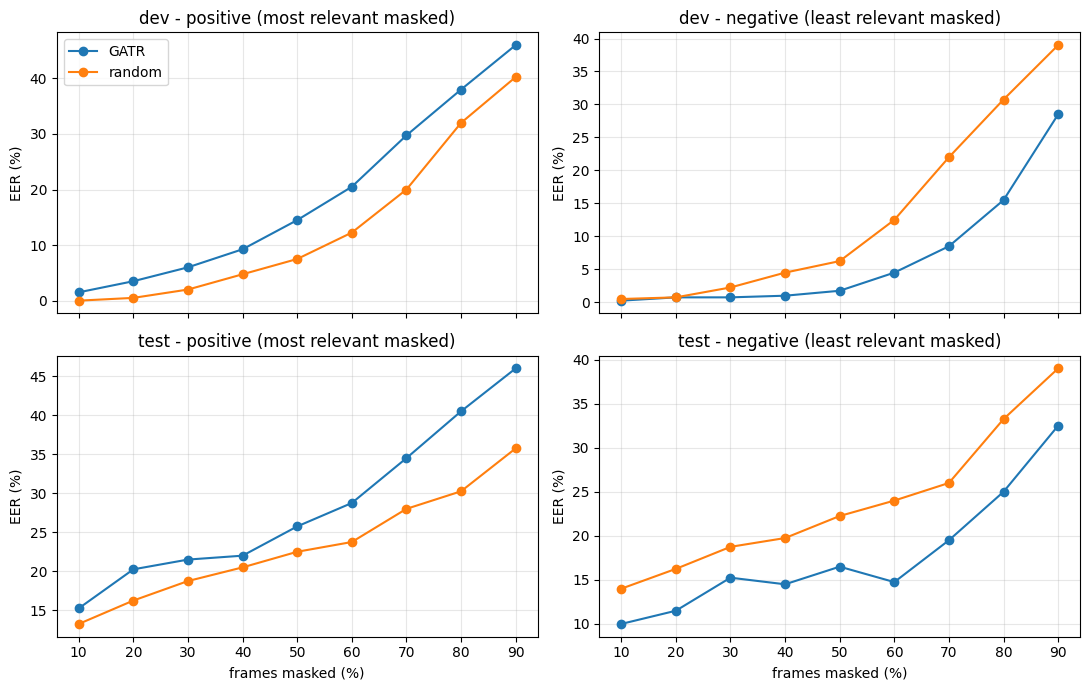

In [20]:
NF, EF, SEEDS, NBOOT = 201, 5, range(PROTOCOL["noise_seeds"]), 2000
FRS = np.round(np.arange(0.1, 0.91, 0.1), 2)
FRAME = np.minimum(np.arange(N) // HOP, NF - 1)
EDGE = np.r_[0:EF, NF - EF:NF]

@torch.no_grad()
def scores_of(batch, chunk=32):
    xb = torch.from_numpy(np.stack(batch))
    return torch.cat([score_of(model(b.cuda())).cpu() for b in xb.split(chunk)]).numpy()

def run_perturbation(name):
    out, smp = os.path.join(XDIR, f"perturbation_{name}.csv"), S[name]
    done = set(pd.read_csv(out).id.astype(str)) if os.path.exists(out) else set()
    buf, t0, n_new = [], time.time(), 0
    for i in range(len(smp)):
        cid = str(smp.id[i])
        if cid in done: continue
        x, batch, meta = WIN[name][i], [], []
        for k in SEEDS:
            rs = np.random.RandomState(CFG["seed"] + (0 if name == "dev" else 1_000_000) + 1000 * k + i)
            noise = (rs.randn(N) * x.std()).astype(np.float32)
            orders = {"gatr": np.lexsort((rs.rand(NF), -MAPS[name][i])), "random": rs.permutation(NF)}
            for m, o in orders.items():
                for f in FRS:
                    kk = int(round(f * NF))
                    for test, fr in [("pos", o[:kk]), ("neg", o[NF - kk:])]:
                        batch.append(np.where(np.isin(FRAME, fr), noise, x)); meta.append((k, m, test, f))
            a = rs.randint(EF, NF - 3 * EF + 1); b = rs.randint(a + EF, NF - 2 * EF + 1)
            for m, fr in [("edges", EDGE), ("random_blocks", np.r_[a:a + EF, b:b + EF])]:
                batch.append(np.where(np.isin(FRAME, fr), noise, x)); meta.append((k, m, "edge", np.nan))
        sc = scores_of(batch)
        buf += [dict(id=cid, label=int(smp.label[i]), seed=k, method=m, test=t, frac=f, score=float(s))
                for (k, m, t, f), s in zip(meta, sc)]
        n_new += 1
        if n_new == 10:
            per = (time.time() - t0) / 10
            print(f"{name}: {per:.1f} s per clip | about {per * (len(smp) - len(done) - n_new) / 60:.0f} min left")
        if n_new % 25 == 0:
            pd.DataFrame(buf).to_csv(out, mode="a", header=not os.path.exists(out), index=False); buf = []
    if buf: pd.DataFrame(buf).to_csv(out, mode="a", header=not os.path.exists(out), index=False)
    print(f"{name}: perturbation scores ready ({(time.time() - t0) / 60:.1f} min this run)")

def eer_fast(M, y):
    o = np.argsort(M, axis=1, kind="stable"); ys = y[o]; r = np.arange(len(M))
    fnr = np.c_[np.zeros(len(M)), np.cumsum(ys, 1) / y.sum()]
    fpr = np.c_[np.ones(len(M)), 1 - np.cumsum(1 - ys, 1) / (1 - y).sum()]
    i = np.abs(fnr - fpr).argmin(1); return 100 * (fnr[r, i] + fpr[r, i]) / 2

RESULTS, CURVES = {}, {}
for name in ["dev", "test"]:
    run_perturbation(name)
    d = pd.read_csv(os.path.join(XDIR, f"perturbation_{name}.csv")); d["id"] = d.id.astype(str)
    ids, y = S[name].id.astype(str).values, S[name].label.values.astype(int)
    p = d[d.test != "edge"].assign(frac=lambda t: t.frac.round(2))
    piv = p.pivot_table(index=["seed", "method", "test", "frac"], columns="id", values="score", aggfunc="first").reindex(columns=ids)
    keys = [(k, m, t, f) for k in SEEDS for m in ["gatr", "random"] for t in ["pos", "neg"] for f in FRS]
    M = piv.loc[keys].values; assert not np.isnan(M).any(), "missing perturbation scores"
    shape = (len(SEEDS), 2, 2, len(FRS))
    E = eer_fast(M, y).reshape(shape); CURVES[name] = E.mean(0)
    chk = max(abs(E.reshape(-1)[j] - eer(y, M[j])[0]) for j in range(0, len(M), 7))
    A = np.trapezoid(E, FRS, axis=-1)
    rs = np.random.RandomState(CFG["seed"] + 7); ib, isp = np.where(y == 1)[0], np.where(y == 0)[0]
    yb = np.r_[np.ones(len(ib)), np.zeros(len(isp))].astype(int); B = np.empty((NBOOT, 2, 2))
    for b in range(NBOOT):
        idx = np.r_[rs.choice(ib, len(ib)), rs.choice(isp, len(isp))]
        B[b] = np.trapezoid(eer_fast(M[:, idx], yb).reshape(shape), FRS, axis=-1).mean(0)
    adv = {"pos": (A.mean(0)[0, 0] - A.mean(0)[1, 0], B[:, 0, 0] - B[:, 1, 0]),
           "neg": (A.mean(0)[1, 1] - A.mean(0)[0, 1], B[:, 1, 1] - B[:, 0, 1])}
    res = dict(auc_gatr_pos=A[:, 0, 0].mean(), auc_random_pos=A[:, 1, 0].mean(), auc_gatr_neg=A[:, 0, 1].mean(),
               auc_random_neg=A[:, 1, 1].mean(), auc_sd_over_seeds_max=A.std(0, ddof=1).max(), eer_check_max_diff=chk)
    for t, (pt, bs) in adv.items():
        lo, hi = np.percentile(bs, [2.5, 97.5]); res.update({f"gatr_advantage_{t}": pt, f"ci_low_{t}": lo, f"ci_high_{t}": hi})
    res["gatr_better_than_random"] = bool(res["ci_low_pos"] > 0 and res["ci_low_neg"] > 0)
    e = d[d.test == "edge"].pivot_table(index="id", columns=["method", "seed"], values="score", aggfunc="first").reindex(ids)
    sign = np.where(y == 1, 1.0, -1.0)
    ch = {m: (sign[:, None] * (e[m].values - S[name].score.values[:, None])).mean(1) for m in ["edges", "random_blocks"]}
    diff = ch["edges"] - ch["random_blocks"]
    bs = [diff[np.r_[rs.choice(ib, len(ib)), rs.choice(isp, len(isp))]].mean() for _ in range(NBOOT)]
    peak_edge = np.isin(MAPS[name].argmax(1), EDGE).mean()
    res.update(peak_on_edges_pct=100 * peak_edge, chance_pct=100 * len(EDGE) / NF,
               edges_minus_random_blocks=diff.mean(), edge_ci_low=np.percentile(bs, 2.5), edge_ci_high=np.percentile(bs, 97.5))
    RESULTS[name] = res

out = pd.DataFrame(RESULTS); out.to_csv(os.path.join(XDIR, "faithfulness.csv"))
print(out.round(3).to_string())
ok = all(RESULTS[s]["gatr_better_than_random"] for s in RESULTS)
print("\nDecision rule:", "GATR is more faithful than a random frame order (both tests, dev and test)" if ok
      else "not shown: the CI includes 0 or favours random in at least one test or split")
for s in RESULTS:
    r = RESULTS[s]
    print(f"{s}: GATR peak on the first/last 0.1 s in {r['peak_on_edges_pct']:.0f}% of clips (chance {r['chance_pct']:.0f}%); "
          f"noise there vs two random 0.1 s blocks: mean margin difference {r['edges_minus_random_blocks']:.3f} "
          f"[{r['edge_ci_low']:.3f}, {r['edge_ci_high']:.3f}] (< 0: edges matter more, > 0: edges matter less)")

fig, ax = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for r_, name in enumerate(["dev", "test"]):
    for c_, t in enumerate(["positive (most relevant masked)", "negative (least relevant masked)"]):
        for m_, m in enumerate(["GATR", "random"]):
            ax[r_, c_].plot(FRS * 100, CURVES[name][m_, c_], marker="o", label=m)
        ax[r_, c_].set_title(f"{name} - {t}"); ax[r_, c_].set_ylabel("EER (%)"); ax[r_, c_].grid(alpha=.3)
for a_ in ax[1]: a_.set_xlabel("frames masked (%)")
ax[0, 0].legend(); plt.tight_layout(); plt.savefig(os.path.join(XDIR, "perturbation_curves.png"), dpi=150); plt.show()

In [21]:
LEVELS = ["head", "head+prompts", "head+prompts+top12", "all"]
def reinit(mod):
    for m in mod.modules():
        if hasattr(m, "reset_parameters"): m.reset_parameters()
LAY = model.enc.ssl.encoder.layers; NL = len(LAY)
def randomize(level):
    torch.manual_seed(CFG["seed"] + 1)
    reinit(model.backend); reinit(model.fc)
    if level >= 1:
        b = math.sqrt(6.0 / (2 * model.enc.P.shape[-1]))
        with torch.no_grad(): model.enc.P.uniform_(-b, b); model.enc.Q.uniform_(-b, b)
        reinit(model.enc.proj)
    if level >= 2:
        for l in LAY[NL // 2:]: reinit(l)
    if level >= 3:
        for l in LAY[:NL // 2]: reinit(l)

y_dev = S["dev"].label.values
rs = np.random.RandomState(CFG["seed"] + 8)
pick = np.r_[rs.choice(np.where(y_dev == 1)[0], 25, replace=False), rs.choice(np.where(y_dev == 0)[0], 25, replace=False)]
state = {k: v.detach().clone() for k, v in model.state_dict().items()}
san = []
try:
    for lv, lname in enumerate(LEVELS):
        model.load_state_dict(state); randomize(lv)
        for i in pick:
            r, lg = gatr_window(WIN["dev"][i], int(y_dev[i]))
            san.append(dict(level=lname, clip=int(i), rho=spearmanr(r, MAPS["dev"][i])[0], score=float(lg[1] - lg[0])))
finally:
    model.load_state_dict(state); model.eval()
r0, _ = gatr_window(WIN["dev"][pick[0]], int(y_dev[pick[0]]))
assert spearmanr(r0, MAPS["dev"][pick[0]])[0] > 0.999, "trained weights NOT restored"
san = pd.DataFrame(san); san.to_csv(os.path.join(XDIR, "sanity_check.csv"), index=False)
orig_score = S["dev"].score.values[pick]
summ = san.groupby("level", sort=False).agg(median_rho=("rho", "median"))
summ["score_rank_corr_with_trained"] = [spearmanr(san[san.level == l].score, orig_score)[0] for l in summ.index]
print("Sanity check (50 dev clips): median Spearman of the GATR map with the trained-model map")
print(summ.round(3).to_string())
v = summ.loc["head+prompts", "median_rho"]
print(f"rule: {v:.3f} after randomizing all trained parameters -> {'FAILS' if v >= 0.5 else 'passes'} (fails if >= 0.5)\n")

def rcq(name, db_below=25):
    rows, y = [], S[name].label.values
    for c, cname in [(1, "bona fide"), (0, "spoof")]:
        tot = {"speech": [0.0, 0], "non-speech": [0.0, 0]}; s_sum, s_n = 0.0, 0
        for i in np.where(y == c)[0]:
            x = WIN[name][i]; db = 10 * np.log10(np.bincount(FRAME, x.astype(float) ** 2) / np.bincount(FRAME) + 1e-12)
            sp = db >= np.percentile(db, 95) - db_below
            h = np.clip(MAPS[name][i].astype(float), 0, None); h = h / h.max() if h.max() > 0 else h
            for cat, msk in [("speech", sp), ("non-speech", ~sp)]: tot[cat][0] += h[msk].sum(); tot[cat][1] += int(msk.sum())
            s_sum += h.sum(); s_n += len(h)
        s_all = s_sum / s_n
        for cat, (sv, nv) in tot.items():
            rows.append(dict(split=name, cls=cname, category=cat, share_of_frames=nv / s_n, RCQ=100 * (sv / max(nv, 1) - s_all) / s_all))
    return rows
rq = pd.DataFrame(sum([rcq(n) for n in ["dev", "test"]], [])); rq.to_csv(os.path.join(XDIR, "rcq_speech.csv"), index=False)
print("RCQ (> 0: the category gets more GATR relevance than average)")
print(rq.pivot_table(index=["split", "cls"], columns="category", values="RCQ").round(1).to_string())
json.dump(dict(sanity=summ.round(4).to_dict(), rcq=rq.round(3).to_dict("records")), open(os.path.join(XDIR, "limits.json"), "w"), indent=2)

Sanity check (50 dev clips): median Spearman of the GATR map with the trained-model map
                    median_rho  score_rank_corr_with_trained
level                                                       
head                     0.569                        -0.454
head+prompts             0.434                        -0.153
head+prompts+top12       0.369                        -0.259
all                      0.080                        -0.222
rule: 0.434 after randomizing all trained parameters -> passes (fails if >= 0.5)

RCQ (> 0: the category gets more GATR relevance than average)
category         non-speech  speech
split cls                          
dev   bona fide         7.0    -1.8
      spoof            36.6   -10.3
test  bona fide        -1.4     0.5
      spoof             5.9    -1.9


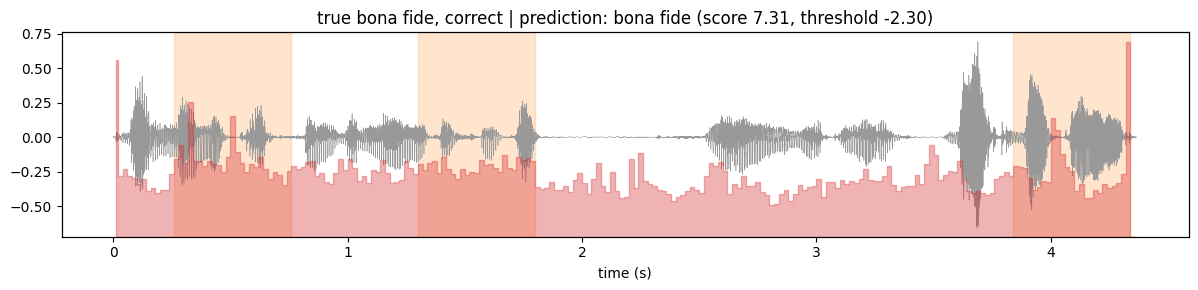

test_1016093: true bona fide, correct | top segments (s): [(0.26, 0.76), (1.3, 1.8), (3.84, 4.34)]


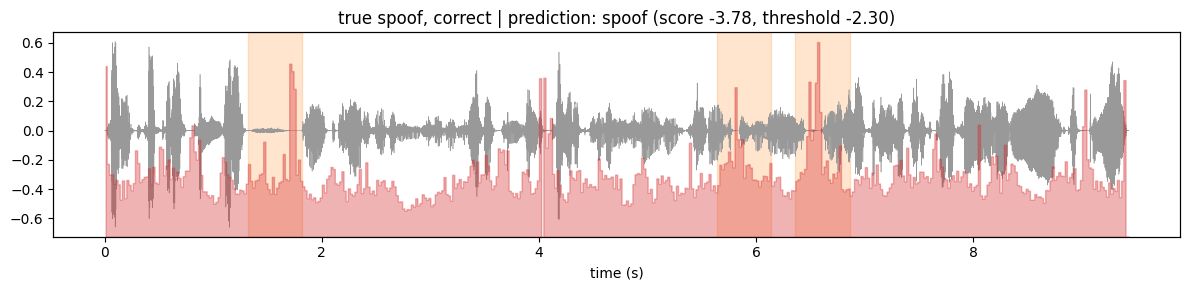

test_0999880: true spoof, correct | top segments (s): [(1.32, 1.82), (5.64, 6.14), (6.36, 6.86)]


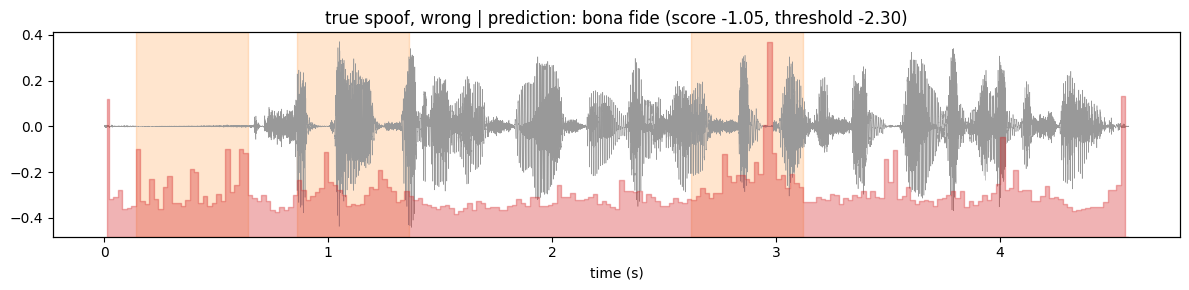

test_1200263: true spoof, wrong | top segments (s): [(0.14, 0.64), (0.86, 1.36), (2.62, 3.12)]
files in /content/drive/MyDrive/nabra/runs/wavlm_large__wpt/xai_gatr : ['example_bona_fide_correct.png', 'example_spoof_correct.png', 'example_spoof_wrong.png', 'faithfulness.csv', 'limits.json', 'maps_dev.npz', 'maps_test.npz', 'perturbation_curves.png', 'perturbation_dev.csv', 'perturbation_test.csv', 'protocol.json', 'rcq_speech.csv', 'sanity_check.csv']


In [25]:
ft = pd.read_csv(os.path.join(RUN_DIR, "final_test_scores.csv")).merge(MAN["track-1_test"][["id", "label", "path"]], on="id")
ex = ft[ft.id.isin(S["test"].id)].assign(pred=lambda d: (d.score >= THR).astype(int)).reset_index(drop=True)
for lab, lname in [(1, "bona fide"), (0, "spoof")]:
    for ok in [True, False]:
        d = ex[(ex.label == lab) & ((ex.pred == ex.label) == ok)]
        if not len(d): continue
        r = d.iloc[0]; e = explain_clip(load_wave(os.path.join(AUDIO_ROOT, r.path)))
        tag = f"true {lname}, {'correct' if ok else 'wrong'}"
        fig = plot_explanation(e, f"{tag} |"); fig.savefig(os.path.join(XDIR, f"example_{lname.replace(' ', '_')}_{'correct' if ok else 'wrong'}.png"), dpi=150)
        plt.show(); print(f"{r.id}: {tag} | top segments (s): {[(round(a, 2), round(b, 2)) for a, b in top_segments(e['frames'])]}")
print("files in", XDIR, ":", sorted(os.listdir(XDIR)))

## 14. Error analysis

decision threshold (from dev) -2.30 | threshold where test FRR = FAR would be 4.14 (shown only, not used)
         clips  bona_fide     spoof   EER   FRR    FAR   errors
dev    20998.0     6952.0   14046.0  0.38  0.37   0.38     79.0
test  144210.0    36903.0  107307.0  8.48  0.18  71.12  76385.0 

test by duration (decision at the dev threshold)
            clips  bona_fide    spoof    EER   FRR    FAR   errors
< 4.04 s  11488.0     2084.0   9404.0  13.81  2.35  48.67   4626.0
4.04-8 s  45614.0    11054.0  34560.0   8.64  0.11  72.77  25160.0
8-12 s    55940.0    13967.0  41973.0   7.73  0.01  72.49  30430.0
12-20 s   30328.0     9798.0  20530.0   7.58  0.02  75.44  15489.0
> 20 s      840.0        0.0    840.0    NaN   NaN  80.95    680.0 

dev by dialect and gender
                   clips  bona_fide    spoof   EER   FRR   FAR  errors
dialect EGY       4529.0     1452.0   3077.0  0.08  0.07  0.26     9.0
        Gulf     15012.0     5015.0   9997.0  0.43  0.50  0.41    66.0
        

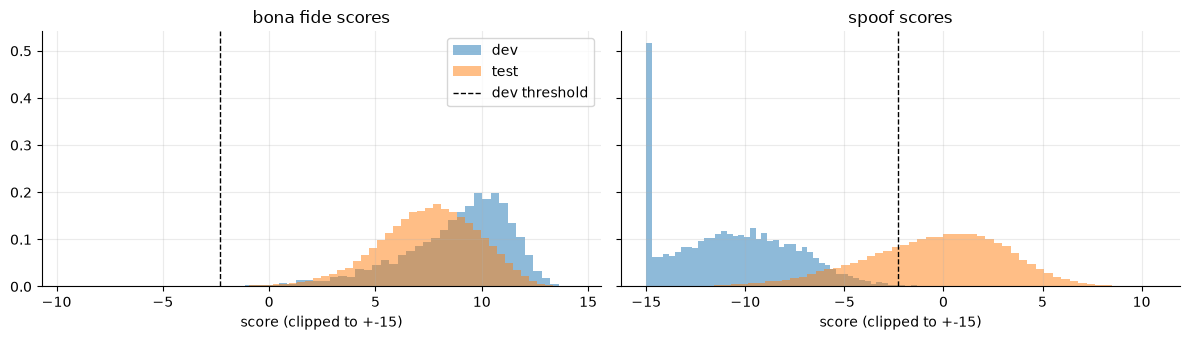

saved in C:\Users\Aisha\nabra_runs\wavlm_large__wpt\error_analysis : ['dev_by_dialect_gender.csv', 'figures', 'metrics_all_runs.csv', 'overall.csv', 'score_distributions.png', 'test_by_duration.csv', 'test_eer_by_duration_all_runs.csv', 'test_worst_errors.csv']


In [11]:
import os, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import roc_curve
if "google.colab" in sys.modules:
    from google.colab import drive; drive.mount("/content/drive")
    root, runs = "/content/drive/MyDrive/nabra", "/content/drive/MyDrive/nabra/runs"
else:
    root, runs = r"C:\Users\Aisha\OneDrive\سطح المكتب\vss\Grad", r"C:\Users\Aisha\nabra_runs"
RUN_DIR = globals().get("RUN_DIR", os.path.join(runs, "wavlm_large__wpt"))
ART_DIR = globals().get("ART_DIR", os.path.join(root, "artifacts", "aradf_eda"))
EA = os.path.join(RUN_DIR, "error_analysis"); os.makedirs(EA, exist_ok=True)

def eer(y, s):
    fpr, tpr, thr = roc_curve(np.asarray(y), np.asarray(s), drop_intermediate=False)
    i = np.nanargmin(np.abs((1 - tpr) - fpr))
    return 100 * (fpr[i] + 1 - tpr[i]) / 2, float(thr[i])

def scores(name, split, cols):
    m = pd.read_csv(os.path.join(ART_DIR, "manifests", f"{split}.csv")); m = m[m["keep"].astype(bool)]
    d = pd.read_csv(os.path.join(RUN_DIR, name)).merge(m[["id"] + cols], on="id")
    assert len(d) == len(m), f"{name}: {len(d)} scores for {len(m)} clips"
    return d
dv = scores("dev_scores.csv", "dev", ["label", "dialect", "gender", "duration_sec"])
te = scores("final_test_scores.csv", "track-1_test", ["label", "duration_sec"])
EER_DEV, THR = eer(dv.label, dv.score)

def rates(d, thr):
    b, s = d[d.label == 1], d[d.label == 0]
    return dict(clips=len(d), bona_fide=len(b), spoof=len(s), EER=eer(d.label, d.score)[0] if len(b) and len(s) else np.nan,
                FRR=100 * (b.score < thr).mean(), FAR=100 * (s.score >= thr).mean(), errors=int((b.score < thr).sum() + (s.score >= thr).sum()))

EER_TE, THR_TE = eer(te.label, te.score)
t1 = pd.DataFrame({"dev": rates(dv, THR), "test": rates(te, THR)}).T
print(f"decision threshold (from dev) {THR:.2f} | threshold where test FRR = FAR would be {THR_TE:.2f} (shown only, not used)")
print(t1.round(2).to_string(), "\n")

bins = [0, 64600 / 16000, 8, 12, 20, np.inf]; names = ["< 4.04 s", "4.04-8 s", "8-12 s", "12-20 s", "> 20 s"]
te["dur"] = pd.cut(te.duration_sec, bins, labels=names, right=False)
t2 = pd.DataFrame({k: rates(g, THR) for k, g in te.groupby("dur", observed=True)}).T
print("test by duration (decision at the dev threshold)"); print(t2.round(2).to_string(), "\n")

t3 = pd.concat({c: pd.DataFrame({k: rates(g, THR) for k, g in dv.groupby(c)}).T for c in ["dialect", "gender"]})
print("dev by dialect and gender"); print(t3.round(2).to_string(), "\n")

te["margin"] = np.where(te.label == 1, te.score - THR, THR - te.score)
worst = te[te.margin < 0].sort_values("margin").groupby("label").head(20)[["id", "label", "duration_sec", "score", "margin"]]
print("most confident mistakes (first 5 per class):"); print(worst.groupby("label").head(5).round(2).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for a, (lab, lname) in zip(ax, [(1, "bona fide"), (0, "spoof")]):
    for d, nm in [(dv, "dev"), (te, "test")]:
        a.hist(d[d.label == lab].score.clip(-15, 15), bins=60, alpha=.5, density=True, label=nm)
    a.axvline(THR, color="k", ls="--", lw=1, label="dev threshold"); a.set_title(f"{lname} scores"); a.set_xlabel("score (clipped to +-15)")
ax[0].legend(); plt.tight_layout(); plt.savefig(os.path.join(EA, "score_distributions.png"), dpi=150); plt.show()

t1.to_csv(os.path.join(EA, "overall.csv")); t2.to_csv(os.path.join(EA, "test_by_duration.csv"))
t3.to_csv(os.path.join(EA, "dev_by_dialect_gender.csv")); worst.to_csv(os.path.join(EA, "test_worst_errors.csv"), index=False)
print("saved in", EA, ":", sorted(os.listdir(EA)))

Track 1 final test (dev rows: whole clip). Threshold metrics use the dev EER threshold of each run; positive class = spoof.
The last column uses the test's own EER threshold: it shows the best possible accuracy, it is not a valid operating point.

run                                     XLS-R Full FT  WavLM Full FT  XLS-R WPT  WavLM WPT (ours)
dev_EER                                          3.61           9.59       0.10              0.38
test_EER                                        16.73          20.27       9.41              8.48
test_AUC                                        90.23          87.75      96.80             97.11
threshold_dev                                    1.77           0.79      -2.94             -2.30
accuracy@dev_thr                                34.95          45.06      34.28             47.03
balanced_accuracy@dev_thr                       56.24          62.16      55.84             64.35
precision_spoof@dev_thr                         99.59          96.

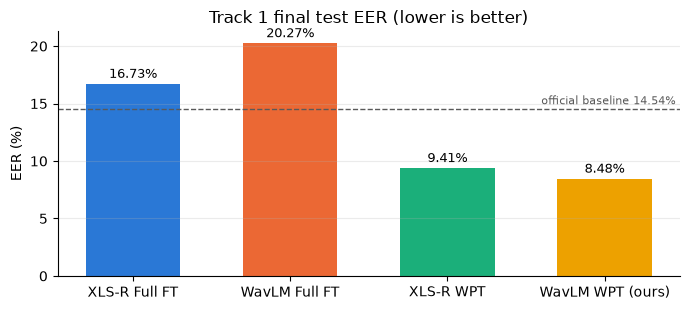

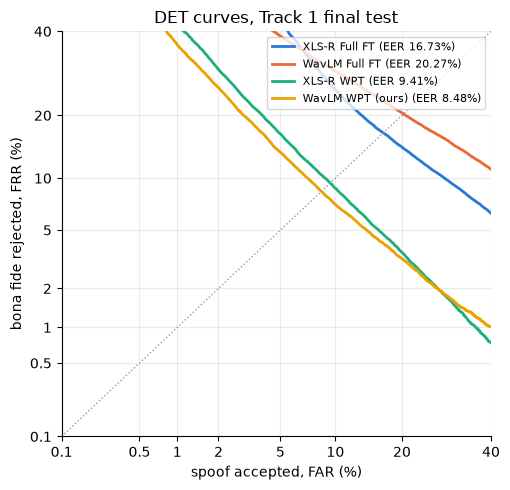

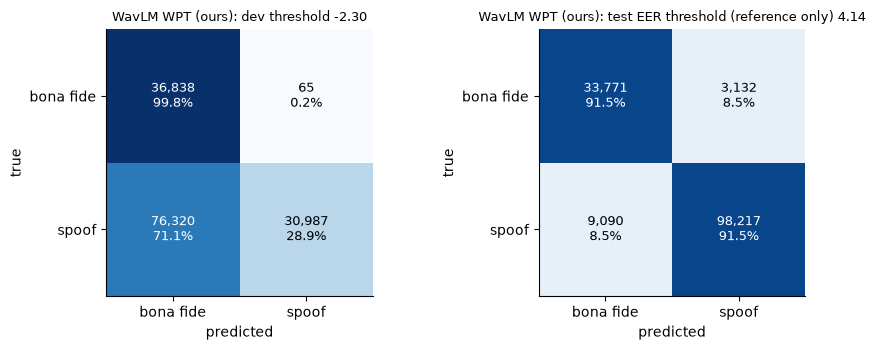

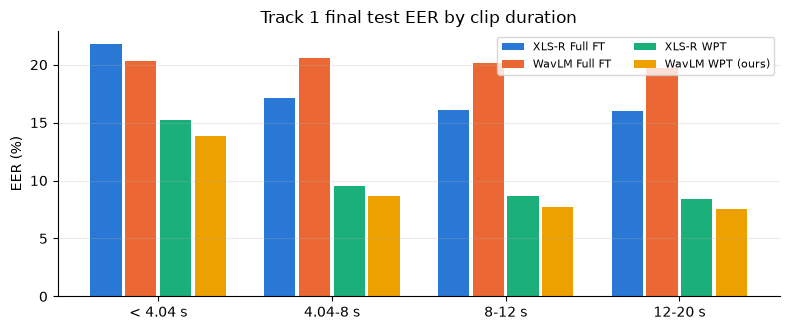

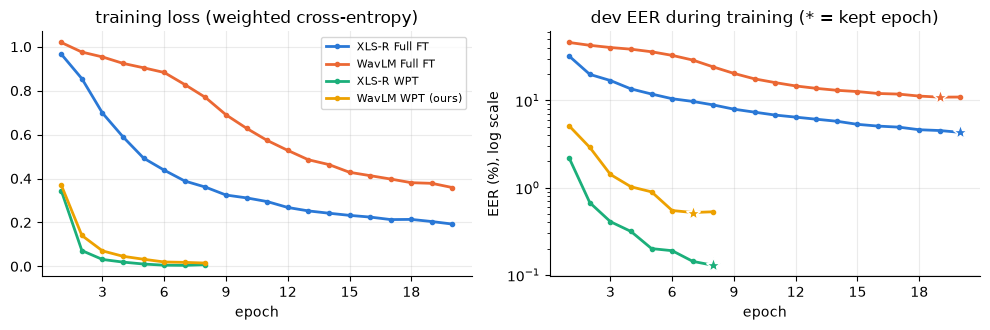

saved in C:\Users\Aisha\nabra_runs\wavlm_large__wpt\error_analysis\figures : ['1_test_eer.png', '2_det_curves.png', '3_confusion_matrices.png', '4_eer_by_duration.png', '5_training_curves.png']


In [12]:
from scipy.stats import norm
from sklearn.metrics import roc_auc_score, det_curve, confusion_matrix
RES = os.path.join(root, "artifacts", "results")
FIG = os.path.join(EA, "figures"); os.makedirs(FIG, exist_ok=True)
RUNS = {"xlsr300m__fullft": "XLS-R Full FT", "wavlm_large__fullft": "WavLM Full FT",
        "xlsr300m__wpt": "XLS-R WPT", "wavlm_large__wpt": "WavLM WPT (ours)"}
COL = dict(zip(RUNS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]))
BASELINE = 14.54
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})

def scores_from(folder, name, split, cols):
    m = pd.read_csv(os.path.join(ART_DIR, "manifests", f"{split}.csv")); m = m[m["keep"].astype(bool)]
    d = pd.read_csv(os.path.join(folder, name)).merge(m[["id"] + cols], on="id")
    assert len(d) == len(m), f"{folder}/{name}: {len(d)} scores for {len(m)} clips"
    return d
D = {r:(scores_from(os.path.join(RES, r), "dev_scores.csv", "dev", ["label"]),
         scores_from(os.path.join(RES, r), "final_test_scores.csv", "track-1_test", ["label", "duration_sec"])) for r in RUNS}

def at(d, thr):
    y, p = (d.label == 0).astype(int), (d.score < thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, p, labels=[0, 1]).ravel()
    prec, rec = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    return dict(accuracy=100 * (tp + tn) / len(d), balanced_accuracy=100 * (rec + tn / (tn + fp)) / 2,
                precision_spoof=100 * prec, recall_spoof=100 * rec, F1_spoof=100 * 2 * prec * rec / max(prec + rec, 1e-12),
                FRR=100 * fp / (tn + fp), FAR=100 * fn / (fn + tp))

rows = []
for r, (dv_, te_) in D.items():
    e_dev, thr_dev = eer(dv_.label, dv_.score); e_te, thr_te = eer(te_.label, te_.score)
    rows.append(dict(run=RUNS[r], dev_EER=e_dev, test_EER=e_te, test_AUC=100 * roc_auc_score(te_.label, te_.score), threshold_dev=thr_dev,
                     **{f"{k}@dev_thr": v for k, v in at(te_, thr_dev).items()},
                     **{"accuracy@test_EER_thr (reference only)": at(te_, thr_te)["accuracy"]}))
M = pd.DataFrame(rows).set_index("run"); M.to_csv(os.path.join(EA, "metrics_all_runs.csv"))
print("Track 1 final test (dev rows: whole clip). Threshold metrics use the dev EER threshold of each run; positive class = spoof.")
print("The last column uses the test's own EER threshold: it shows the best possible accuracy, it is not a valid operating point.\n")
print(M.T.round(2).to_string())

def save(fig, name):
    fig.tight_layout(); fig.savefig(os.path.join(FIG, name), dpi=150, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(figsize=(7, 3.2))
b = ax.bar(list(RUNS.values()), M.test_EER, color=[COL[r] for r in RUNS], width=.6)
ax.bar_label(b, fmt="%.2f%%", padding=2, fontsize=9)
ax.axhline(BASELINE, color="0.35", ls="--", lw=1); ax.text(3.45, BASELINE + .4, f"official baseline {BASELINE}%", ha="right", fontsize=8, color="0.35")
ax.set_ylabel("EER (%)"); ax.set_title("Track 1 final test EER (lower is better)"); ax.grid(axis="x", visible=False)
save(fig, "1_test_eer.png")

ticks = np.array([.1, .5, 1, 2, 5, 10, 20, 40]) / 100
fig, ax = plt.subplots(figsize=(5.2, 5))
for r, (_, te_) in D.items():
    fpr, fnr, _ = det_curve(te_.label, te_.score)
    ax.plot(norm.ppf(np.clip(fpr, 1e-4, 1 - 1e-4)), norm.ppf(np.clip(fnr, 1e-4, 1 - 1e-4)), lw=2, color=COL[r],
            label=f"{RUNS[r]} (EER {M.loc[RUNS[r], 'test_EER']:.2f}%)")
ax.plot(norm.ppf(ticks[[0, -1]]), norm.ppf(ticks[[0, -1]]), color="0.6", lw=1, ls=":")
for setter in (ax.set_xticks, ax.set_yticks): setter(norm.ppf(ticks))
ax.set_xticklabels([f"{100 * t:g}" for t in ticks]); ax.set_yticklabels([f"{100 * t:g}" for t in ticks])
ax.set_xlim(norm.ppf(ticks[[0, -1]])); ax.set_ylim(norm.ppf(ticks[[0, -1]]))
ax.set_xlabel("spoof accepted, FAR (%)"); ax.set_ylabel("bona fide rejected, FRR (%)"); ax.set_title("DET curves, Track 1 final test")
ax.legend(fontsize=8, loc="upper right"); save(fig, "2_det_curves.png")

best = "wavlm_large__wpt"; dv_, te_ = D[best]
fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
for a, (thr, ttl) in zip(axs, [(eer(dv_.label, dv_.score)[1], "dev threshold"), (eer(te_.label, te_.score)[1], "test EER threshold (reference only)")]):
    cm = confusion_matrix(te_.label, (te_.score >= thr).astype(int), labels=[1, 0])
    a.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1); a.grid(False)
    for i in range(2):
        for j in range(2):
            v = cm[i, j] / cm[i].sum()
            a.text(j, i, f"{cm[i, j]:,}\n{100 * v:.1f}%", ha="center", va="center", fontsize=9, color="white" if v > .6 else "black")
    a.set_xticks([0, 1], ["bona fide", "spoof"]); a.set_yticks([0, 1], ["bona fide", "spoof"])
    a.set_xlabel("predicted"); a.set_ylabel("true"); a.set_title(f"{RUNS[best]}: {ttl} {thr:.2f}", fontsize=9)
save(fig, "3_confusion_matrices.png")

bins = [0, 64600 / 16000, 8, 12, 20]; names = ["< 4.04 s", "4.04-8 s", "8-12 s", "12-20 s"]
by_dur = pd.DataFrame({RUNS[r]: [eer(g.label, g.score)[0] for _, g in te_.groupby(pd.cut(te_.duration_sec, bins, labels=names, right=False), observed=True)]
                       for r, (_, te_) in D.items()}, index=names)
by_dur.to_csv(os.path.join(EA, "test_eer_by_duration_all_runs.csv"))
fig, ax = plt.subplots(figsize=(8, 3.4)); w = .2
for k, r in enumerate(RUNS):
    ax.bar(np.arange(len(names)) + (k - 1.5) * w, by_dur[RUNS[r]], w * .9, color=COL[r], label=RUNS[r])
ax.set_xticks(range(len(names)), names); ax.set_ylabel("EER (%)"); ax.set_title("Track 1 final test EER by clip duration")
ax.grid(axis="x", visible=False); ax.legend(fontsize=8, ncol=2); save(fig, "4_eer_by_duration.png")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
for r in RUNS:
    log = pd.read_csv(os.path.join(RES, r, "train_log.csv"))
    axs[0].plot(log.epoch, log.train_loss, marker="o", ms=3, lw=2, color=COL[r], label=RUNS[r])
    axs[1].plot(log.epoch, log.dev_eer, marker="o", ms=3, lw=2, color=COL[r], label=RUNS[r])
    bst = log[log.best].iloc[-1]; axs[1].plot(bst.epoch, bst.dev_eer, marker="*", ms=11, color=COL[r], mec="white")
axs[0].set_title("training loss (weighted cross-entropy)"); axs[1].set_title("dev EER during training (* = kept epoch)")
axs[1].set_yscale("log"); axs[1].set_ylabel("EER (%), log scale")
for a in axs: a.set_xlabel("epoch"); a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
axs[0].legend(fontsize=8); save(fig, "5_training_curves.png")
print("saved in", FIG, ":", sorted(os.listdir(FIG)))